# AIT Chatbot

In [7]:
class CollegeInformationChatbot:

    # CONSTRUCTOR:
    # Automatically executes when an object is created.
    # self refers to the current object.
    def __init__(self):

        # PERFORMANCE MEASURE:
        # Stores chatbot performance counters.
        self.performance = {
            "correct_response": 0,
            "helpful_response": 0,
            "polite_response": 0
        }

        # ENVIRONMENT:
        self.environment = "Student interacting with college information chatbot"

        # ACTUATORS:
        self.actuators = "Text response displayed to the student"

        # SENSORS:
        self.sensors = "Student's text input"

        # KNOWLEDGE BASE:
        # Stores predefined questions and corresponding answers.
        self.responses = {

            "hello": "Hello! Welcome to the College Information Chatbot.",
            "hi": "Hi! How can I help you?",

            "what courses are available":
                "The college offers Computer Science, IT, Electronics, Mechanical, Civil and Electrical Engineering.",

            "what is the fee":
                "The approximate tuition fee is Rs. 3,48,000.",

            "what is the fee for it":
                "The approximate fee for the IT department is Rs. 3,48,000.",

            "what is the nirf ranking":
                "The college's NIRF ranking is approximately 200.",

            "what is the average package":
                "The average placement package is approximately Rs. 13.5 LPA.",

            "what is the admission process":
                "The admission process includes checking eligibility, application, entrance examination or merit selection, document verification and fee payment.",

            "what is the qualification":
                "Students generally need to complete 12th standard and meet the required entrance examination criteria.",

            "is hostel available":
                "Yes, hostel facilities are available for students.",

            "is placement available":
                "Yes, the college provides placement assistance.",

            "what is the qualification of teacher":
                "Most teachers are highly qualified and many faculty members are pursuing or have completed a PhD.",

            "thank you": "You're welcome! I'm happy to help.",
            "thanks":    "You're welcome! I'm happy to help.",

            "bye":  "Goodbye! Have a great day!",
            "exit": "Goodbye! Have a great day!",
            "quit": "Goodbye! Have a great day!"
        }

        # KEYWORD ALIASES:
        # Maps short user words to full response keys.
        # FIX: original code matched full phrases against short input —
        #      e.g. "what is the admission process" in "admission" → always False.
        #      Aliases solve this by checking short keywords first.
        self.aliases = {
            "admission"    : "what is the admission process",
            "fee"          : "what is the fee",
            "course"       : "what courses are available",
            "courses"      : "what courses are available",
            "nirf"         : "what is the nirf ranking",
            "ranking"      : "what is the nirf ranking",
            "package"      : "what is the average package",
            "placement"    : "is placement available",
            "hostel"       : "is hostel available",
            "teacher"      : "what is the qualification of teacher",
            "faculty"      : "what is the qualification of teacher",
            "qualification": "what is the qualification",
            "hello"        : "hello",
            "hi"           : "hi",
            "thank you"    : "thank you",
            "thanks"       : "thanks",
            "bye"          : "bye",
            "exit"         : "exit",
            "quit"         : "quit"
        }


    # SENSOR FUNCTION:
    # Receives and processes student input.
    def sense(self, user_input):

        print("\n[SENSOR] Receiving student input...")

        # lower() converts text into lowercase.
        # strip() removes unnecessary spaces.
        return user_input.lower().strip()


    # THINKING FUNCTION:
    # Searches the knowledge base for a matching answer.
    def think(self, user_input):

        print("[THINKING] Understanding the question...")

        # STEP 1: Check aliases first.
        # Aliases handle short keywords like "admission", "fee", "hostel".
        # Sort aliases by keyword length (longest first) for specificity.
        for alias, response_key in sorted(
            self.aliases.items(),
            key=lambda item: len(item[0]),
            reverse=True
        ):
            if alias in user_input:
                print("[THINKING] Matching information found!")
                return self.responses[response_key]

        # STEP 2: Check full phrase match as fallback.
        # Sort keywords by length in descending order.
        # This checks longer and more specific questions first.
        for keyword, response in sorted(
            self.responses.items(),
            key=lambda item: len(item[0]),
            reverse=True
        ):
            if keyword in user_input:
                print("[THINKING] Matching information found!")
                return response

        # If no matching keyword is found.
        print("[THINKING] No matching information found.")

        return (
            "Sorry, I don't understand that question. "
            "Please ask about courses, fees, admission, "
            "placements, hostel or faculty."
        )


    # ACTUATOR FUNCTION:
    # Displays the chatbot response.
    def act(self, response):

        print("[ACTUATOR] Displaying response to student...")

        print("Chatbot:", response)


    # PERFORMANCE EVALUATION FUNCTION:
    # Updates performance counters.
    def evaluate(self, response):

        # If the response is not the default error response,
        # increase the correct response counter.
        if not response.startswith("Sorry, I don't understand"):
            self.performance["correct_response"] += 1

        # If response contains more than 10 characters,
        # increase the helpful response counter.
        if len(response) > 10:
            self.performance["helpful_response"] += 1

        # Count every generated response as polite.
        self.performance["polite_response"] += 1


    # MAIN AGENT FUNCTION:
    # Connects sensing, thinking, evaluation and action.
    def run(self, user_input):

        # STEP 1: SENSING
        sensed_input = self.sense(user_input)

        # STEP 2: THINKING
        response = self.think(sensed_input)

        # STEP 3: PERFORMANCE EVALUATION
        self.evaluate(response)

        # STEP 4: ACTUATION
        self.act(response)

        # Return the final response.
        return response


    # PEAS DISPLAY FUNCTION:
    # Displays all four PEAS components.
    def display_peas(self):

        print("\n========== PEAS REPRESENTATION ==========")

        print("Performance Measure:", self.performance)
        print("Environment:", self.environment)
        print("Actuators:", self.actuators)
        print("Sensors:", self.sensors)

        print("=========================================")


# ==========================================
# OBJECT CREATION
# ==========================================

# Creates an object of CollegeInformationChatbot.
# Automatically calls the constructor __init__().
chatbot = CollegeInformationChatbot()


# ==========================================
# DISPLAY PEAS REPRESENTATION
# ==========================================

# Calls display_peas() using the chatbot object.
chatbot.display_peas()


# ==========================================
# WELCOME MESSAGE
# ==========================================

print("\n==============================================")
print("       COLLEGE INFORMATION CHATBOT")
print("==============================================")

print("Ask questions about the college.")
print("Type 'bye', 'exit' or 'quit' to stop.")

print("==============================================")


# ==========================================
# MAIN PROGRAM LOOP
# ==========================================

# Runs continuously until the user enters an exit command.
while True:

    # Receive input from the student.
    user_input = input("\nYou: ")

    # Process input using the chatbot agent.
    chatbot.run(user_input)

    # Check whether the user wants to exit.
    # Also supports phrases like 'bye chatbot'.
    if user_input.lower().strip().split()[0] in ["bye", "exit", "quit"]:

        print("\nChatbot session ended.")

        break


# ==========================================
# FINAL PERFORMANCE REPORT
# ==========================================

print("\n==============================================")
print("          PERFORMANCE MEASURE")
print("==============================================")

# Display all performance counters.
for measure, score in chatbot.performance.items():

    print(measure, ":", score)

print("==============================================")


========== PEAS REPRESENTATION ==========
Performance Measure: {'correct_response': 0, 'helpful_response': 0, 'polite_response': 0}
Environment: Student interacting with college information chatbot
Actuators: Text response displayed to the student
Sensors: Student's text input

       COLLEGE INFORMATION CHATBOT
Ask questions about the college.
Type 'bye', 'exit' or 'quit' to stop.



You:  admission



[SENSOR] Receiving student input...
[THINKING] Understanding the question...
[THINKING] Matching information found!
[ACTUATOR] Displaying response to student...
Chatbot: The admission process includes checking eligibility, application, entrance examination or merit selection, document verification and fee payment.



You:  exit



[SENSOR] Receiving student input...
[THINKING] Understanding the question...
[THINKING] Matching information found!
[ACTUATOR] Displaying response to student...
Chatbot: Goodbye! Have a great day!

Chatbot session ended.

          PERFORMANCE MEASURE
correct_response : 2
helpful_response : 2
polite_response : 2


In [ ]:
```python
# Define a class named CollegeInformationChatbot
class CollegeInformationChatbot:

    # CONSTRUCTOR
    # __init__() automatically executes when an object is created.
    # self refers to the current object of the class.
    def __init__(self):

        # PERFORMANCE MEASURE:
        # Stores the performance counters of the chatbot.
        # Initially, all counters are set to zero.
        self.performance = {
            "correct_response": 0,
            "helpful_response": 0,
            "polite_response": 0
        }

        # ENVIRONMENT:
        # Describes the surroundings in which the agent operates.
        self.environment = "Student interacting with college information chatbot"

        # ACTUATORS:
        # Define how the chatbot performs actions.
        # Here, the chatbot displays text responses.
        self.actuators = "Text response displayed to the student"

        # SENSORS:
        # Define how the chatbot receives information.
        # Here, the chatbot receives text input from the student.
        self.sensors = "Student's text input"

        # KNOWLEDGE BASE:
        # Dictionary containing predefined questions and their answers.
        # Keys represent questions and values represent responses.
        self.responses = {

            "hello": "Hello! Welcome to the College Information Chatbot.",
            "hi": "Hi! How can I help you?",

            "what courses are available":
                "The college offers Computer Science, IT, Electronics, Mechanical, Civil and Electrical Engineering.",

            "what is the fee":
                "The approximate tuition fee is Rs. 3,48,000.",

            "what is the fee for it":
                "The approximate fee for the IT department is Rs. 3,48,000.",

            "what is the nirf ranking":
                "The college's NIRF ranking is approximately 200.",

            "what is the average package":
                "The average placement package is approximately Rs. 13.5 LPA.",

            "what is the admission process":
                "The admission process includes checking eligibility, application, entrance examination or merit selection, document verification and fee payment.",

            "what is the qualification":
                "Students generally need to complete 12th standard and meet the required entrance examination criteria.",

            "is hostel available":
                "Yes, hostel facilities are available for students.",

            "is placement available":
                "Yes, the college provides placement assistance.",

            "what is the qualification of teacher":
                "Most teachers are highly qualified and many faculty members are pursuing or have completed a PhD.",

            "thank you": "You're welcome! I'm happy to help.",
            "thanks": "You're welcome! I'm happy to help.",

            "bye": "Goodbye! Have a great day!",
            "exit": "Goodbye! Have a great day!",
            "quit": "Goodbye! Have a great day!"
        }


    # SENSOR FUNCTION
    # Receives information from the student.
    def sense(self, user_input):

        print("\n[SENSOR] Receiving student input...")

        # lower() converts the input into lowercase.
        # strip() removes extra spaces from beginning and end.
        # return sends the processed input back to the calling function.
        return user_input.lower().strip()


    # THINKING FUNCTION
    # Processes the input and searches for a matching answer.
    def think(self, user_input):

        print("[THINKING] Understanding the question...")

        # items() returns all key-value pairs from the dictionary.
        # keyword stores the question/key.
        # response stores its corresponding answer/value.
        for keyword, response in self.responses.items():

            # Checks whether the dictionary keyword exists in user_input.
            # in is used to check substring membership.
            if keyword in user_input:

                print("[THINKING] Matching information found!")

                # return sends the matching answer back to run().
                return response

        # Executes when no matching keyword is found.
        print("[THINKING] No matching information found.")

        # Returns a default response.
        return (
            "Sorry, I don't understand that question. "
            "Please ask about courses, fees, admission, "
            "placements, hostel or faculty."
        )


    # ACTUATOR FUNCTION
    # Performs an action by displaying the chatbot's response.
    def act(self, response):

        print("[ACTUATOR] Displaying response to student...")

        # Displays the final answer on the screen.
        print("Chatbot:", response)


    # PERFORMANCE EVALUATION FUNCTION
    # Evaluates and updates the chatbot's performance counters.
    def evaluate(self, response):

        # Checks whether the response contains the word "sorry".
        # If not, increase the correct response counter by 1.
        if "sorry" not in response.lower():
            self.performance["correct_response"] += 1

        # len() calculates the number of characters in the response.
        # If response length is greater than 10,
        # increase the helpful response counter.
        if len(response) > 10:
            self.performance["helpful_response"] += 1

        # Increase polite response counter for every response.
        self.performance["polite_response"] += 1


    # MAIN AGENT FUNCTION
    # Coordinates all the main functions of the chatbot.
    def run(self, user_input):

        # STEP 1: SENSING
        # Calls sense() to receive and process student input.
        # The processed input is stored in sensed_input.
        sensed_input = self.sense(user_input)

        # STEP 2: THINKING
        # Calls think() to search for a matching answer.
        # The selected answer is stored in response.
        response = self.think(sensed_input)

        # STEP 3: PERFORMANCE EVALUATION
        # Calls evaluate() to update performance counters.
        self.evaluate(response)

        # STEP 4: ACTUATION
        # Calls act() to display the answer to the student.
        self.act(response)

        # Returns the selected response to the caller.
        return response


    # PEAS DISPLAY FUNCTION
    # Displays the four components of the PEAS framework.
    def display_peas(self):

        print("\n========== PEAS REPRESENTATION ==========")

        # Displays Performance Measure.
        print("Performance Measure:", self.performance)

        # Displays Environment.
        print("Environment:", self.environment)

        # Displays Actuators.
        print("Actuators:", self.actuators)

        # Displays Sensors.
        print("Sensors:", self.sensors)

        print("=========================================")


# ==========================================
# OBJECT CREATION
# ==========================================

# Creates an object named chatbot from the class.
# The constructor __init__() automatically executes.
chatbot = CollegeInformationChatbot()


# ==========================================
# DISPLAY PEAS REPRESENTATION
# ==========================================

# chatbot is the object.
# Dot (.) operator accesses a class method.
# display_peas() calls the method using the chatbot object.
# It displays Performance, Environment, Actuators and Sensors.
chatbot.display_peas()


# ==========================================
# CHATBOT WELCOME MESSAGE
# ==========================================

print("\n==============================================")
print("       COLLEGE INFORMATION CHATBOT")
print("==============================================")

print("Ask questions about the college.")
print("Type 'bye', 'exit' or 'quit' to stop.")

print("==============================================")


# ==========================================
# INFINITE LOOP
# ==========================================

# while True creates an infinite loop.
# The chatbot continuously accepts questions until break executes.
while True:

    # input() takes a question from the student.
    # The entered question is stored in user_input.
    user_input = input("\nYou: ")

    # Calls run() using the chatbot object.
    # Internally, run() calls:
    # 1. sense()
    # 2. think()
    # 3. evaluate()
    # 4. act()
    chatbot.run(user_input)

    # lower() converts input to lowercase.
    # strip() removes unnecessary spaces.
    # Checks whether the student wants to exit.
    if user_input.lower().strip() in ["bye", "exit", "quit"]:

        # break terminates the infinite while loop.
        break


# ==========================================
# FINAL PERFORMANCE REPORT
# ==========================================

print("\n==============================================")
print("          PERFORMANCE MEASURE")
print("==============================================")

# items() returns key-value pairs from performance dictionary.
# measure stores the performance name.
# score stores its corresponding counter value.
for measure, score in chatbot.performance.items():

    # Displays each performance measure and its score.
    print(measure, ":", score)

print("==============================================")
```
1. Basic Questions About Your Project

Q1. What is the objective of your project?

Ans: The objective is to develop a College Information Chatbot that provides students with information about courses, fees, admissions, placements, hostel facilities and faculty.

Q2. What is a chatbot?

Ans: A chatbot is a software application that interacts with users through text or voice and provides answers to their queries.

Q3. Which programming language did you use?

Ans: Python.

Q4. What type of chatbot have you developed?

Ans: I have developed a rule-based chatbot that uses predefined questions and answers stored in a dictionary.

Q5. Does your chatbot use Machine Learning?

Ans: No. It uses predefined rules and keyword matching. It does not train on datasets.

Q6. What is an intelligent agent?

Ans: An intelligent agent is a system that observes its environment through sensors and performs actions through actuators to achieve a particular goal.

Q7. Why is your chatbot called an intelligent agent?

Ans: Because it receives input from students, processes the input, selects an appropriate response and displays the response.

2. PEAS Framework Questions

Q8. What is PEAS?

Ans: PEAS stands for:

P – Performance Measure
E – Environment
A – Actuators
S – Sensors

It is used to describe the working environment of an intelligent agent.

Q9. Explain PEAS in your project.

Ans:

Component	Implementation
Performance Measure	Correct, helpful and polite response counters
Environment	Student interacting with chatbot
Actuators	Displaying text responses
Sensors	Student's text input

Q10. What is a performance measure?

Ans: It evaluates how well an intelligent agent performs its task.

Q11. What is the environment in your project?

Ans: The environment is the student interacting with the college information chatbot.

Q12. What are sensors?

Ans: Sensors collect information from the environment. In my project, the sensor receives text input from students.

Q13. What are actuators?

Ans: Actuators perform actions. In my project, the actuator displays the chatbot's response.

Q14. Give an example of sensors and actuators in real life.

Ans:

Human: Eyes are sensors; hands and legs act as actuators.
Self-driving car: Cameras are sensors; steering and braking systems are actuators.
Chatbot: Text input is the sensor; displayed response is the actuator.

Q15. What are the three performance measures in your project?

Ans:

Correct response
Helpful response
Polite response
3. Python and OOP Questions

Q16. What is a class?

Ans: A class is a blueprint or template used to create objects.

Q17. What is an object?

Ans: An object is an instance of a class.

Example:

chatbot = CollegeInformationChatbot()

Here, chatbot is an object.

Q18. What is a constructor?

Ans: A constructor is a special method that initializes an object when it is created.

In Python, it is written as:

def __init__(self):

Q19. What is self?

Ans: self refers to the current object of the class. It is used to access variables and methods belonging to that object.

Q20. Why do we use self.responses?

Ans: To access the responses dictionary belonging to the current chatbot object.

Q21. What is the difference between a local variable and an instance variable?

Ans:

Local variable	Instance variable
Declared inside a method.	Declared using self.
Available within that method.	Accessible through the object.
Example: response	Example: self.responses

Q22. What is a method?

Ans: A method is a function defined inside a class.

Examples from my project:

sense()
think()
act()
evaluate()
run()
display_peas()

Q23. What is the dot operator?

Ans: The dot operator (.) is used to access methods and attributes of an object.

Example:

chatbot.display_peas()

It calls the display_peas() method using the chatbot object.

4. Questions About Individual Functions

Q24. What is the purpose of sense()?

Ans: It receives the student's input and converts it into lowercase while removing unnecessary spaces.

Q25. Why do we use lower()?

Ans: To convert all characters into lowercase so that uppercase and lowercase inputs are treated similarly.

Example:

"HELLO".lower()

Output:

hello

Q26. Why do we use strip()?

Ans: To remove unnecessary spaces from the beginning and end of a string.

Example:

"  hello  ".strip()

Output:

hello

Q27. What is the purpose of think()?

Ans: It searches for a matching keyword in the knowledge base and returns the corresponding answer.

Q28. What does self.responses.items() do?

Ans: It returns all key-value pairs from the dictionary.

Example:

responses = {"hello": "Hi"}

Using:

responses.items()

Returns:

dict_items([('hello', 'Hi')])

Q29. What does if keyword in user_input mean?

Ans: It checks whether the predefined keyword exists inside the student's input.

Q30. What happens if no matching keyword is found?

Ans: The chatbot returns a default response saying that it does not understand the question.

Q31. What is the purpose of act()?

Ans: It displays the selected response to the student.

Q32. What is the purpose of evaluate()?

Ans: It updates the performance counters based on the generated response.

Q33. What is the purpose of run()?

Ans: It connects the four major operations of the chatbot:

Sensing
Thinking
Performance evaluation
Acting

Q34. What is the purpose of display_peas()?

Ans: It displays the PEAS components of the chatbot.

Q35. What does return do?

Ans: It sends a value back to the function that called it.

5. Performance Measure Questions

Q36. Why are all performance counters initialized to zero?

Ans: Because initially, no conversation has taken place and no responses have been evaluated.

Q37. Explain this statement:

self.performance["correct_response"] += 1

Ans: It increases the correct response counter by one.

Q38. Why do you use len(response) > 10?

Ans: It checks whether the response contains more than 10 characters. If true, the helpful response counter increases.

Q39. Why do you use "sorry" not in response.lower()?

Ans: It checks whether the response contains the word "sorry". If it does not, the correct response counter increases.

Q40. Does your chatbot calculate actual accuracy?

Ans: No. It maintains basic performance counters based on predefined conditions. These counters do not guarantee that a response is factually correct or helpful.

Q41. Why do you increase the polite response counter for every response?

Ans: In this implementation, every generated response is counted as polite. However, this is a simplified assumption and does not actually evaluate politeness.

6. Agent Architecture Questions

Q42. What are the different types of intelligent agents?

Ans:

Simple Reflex Agent
Model-Based Reflex Agent
Goal-Based Agent
Utility-Based Agent
Learning Agent

Q43. Which type of agent is your chatbot?

Ans: It is a simple rule-based agent that behaves similarly to a simple reflex agent because it selects responses based on predefined conditions.

Q44. What is a simple reflex agent?

Ans: It selects actions based on the current percept using predefined condition-action rules.

Q45. What is a knowledge base?

Ans: A knowledge base is a collection of stored information used by an intelligent system to answer queries or make decisions.

In my project:

self.responses = {}

acts as the knowledge base.

Q46. What is the difference between a rule-based chatbot and an AI chatbot?

Rule-based chatbot	AI chatbot
Uses predefined rules.	Can use ML or language models.
Matches keywords.	Can understand context and intent.
Limited responses.	More flexible responses.
Does not learn automatically.	Can learn through training or feedback.
7. Loop and Conditional Questions

Q47. Why do you use while True?

Ans: It creates an infinite loop so that the chatbot continuously accepts questions until the user enters an exit command.

Q48. What is the purpose of break?

Ans: It terminates the loop immediately.

Q49. Why do you use if-else conditions?

Ans: To make decisions based on whether a particular condition is true or false.

Q50. What happens when the user enters bye?

Ans:

The input is received.
The chatbot finds the matching goodbye response.
Performance counters are updated.
The goodbye message is displayed.
The break statement terminates the loop.

Q51. Why do you use in ["bye", "exit", "quit"]?

Ans: To check whether the user's input matches any of the three predefined exit commands.

Q52. What is an infinite loop?

Ans: A loop that continues executing until a termination condition is reached.

8. Advanced Viva Questions

Q53. What is NLP?

Ans: NLP stands for Natural Language Processing. It is a field of AI that allows computers to understand, process and generate human language.

Q54. Does your chatbot use NLP?

Ans: No. It performs basic text preprocessing using lower() and strip() and uses substring matching. It does not implement NLP techniques such as tokenization or intent recognition.

Q55. What is the limitation of your chatbot?

Ans:

It supports only predefined questions.
It cannot properly understand spelling mistakes.
It cannot understand complex sentences.
It cannot generate new answers.
It depends on the stored knowledge base.

Q56. How can you improve your chatbot?

Ans:

Add more questions and answers.
Implement NLP.
Use machine learning for intent classification.
Connect it to a database.
Integrate a language model for more flexible responses.

Q57. What is the difference between print() and return?

Ans:

print()	return
Displays information on the screen.	Sends a value back to the caller.
Does not return the displayed text.	Can return strings, numbers, objects, etc.

Q58. What is dictionary data structure?

Ans: A dictionary is a Python data structure that stores data in key-value pairs.

Q59. What happens if two keywords match the same user input?

Ans: The first matching keyword in dictionary insertion order is returned because the function immediately executes return response.

Q60. Can multiple chatbot objects be created from the same class?

Ans: Yes. Each object gets its own instance variables and performance counters.

# Prac - 1 Smart Home Automation System using Intelligent Agents

In [12]:

# PEAS Representation
# Performance: Measures agent actions
# Environment: Smart Home
# Sensors: Temperature, Light, Motion
# Actuators: AC, Heater, Light

# Agent 1: Simple Reflex Agent
def simple_agent(temp, dark, person):
    actions = []

    if temp is None:
        return ["Cannot decide"]

    if temp > 30:
        actions.append("AC ON")
    elif temp < 18:
        actions.append("Heater ON")

    if person and dark:
        actions.append("Light ON")
    elif not person:
        actions.append("Light OFF")

    return actions if actions else ["No change"]


# Agent 2: Model-Based Reflex Agent
state = {"temp": 25, "ac": False, "heater": False, "light": False}

def model_agent(temp, dark, person):
    actions = []

    if temp is None:
        temp = state["temp"]
    else:
        state["temp"] = temp

    if temp > 30 and not state["ac"]:
        actions.append("AC ON")
        state["ac"] = True
        state["heater"] = False

    elif temp < 18 and not state["heater"]:
        actions.append("Heater ON")
        state["heater"] = True
        state["ac"] = False

    elif 18 <= temp <= 30:
        if state["ac"] or state["heater"]:
            actions.append("AC/Heater OFF")
        state["ac"] = False
        state["heater"] = False

    if person and dark and not state["light"]:
        actions.append("Light ON")
        state["light"] = True

    elif not person and state["light"]:
        actions.append("Light OFF")
        state["light"] = False

    return actions if actions else ["No change"]


# Performance Measurement
performance = {"runs": 0, "reflex": 0, "model": 0, "sensor_failure": 0}

def update_performance(temp, r, m):
    performance["runs"] += 1

    if r != ["Cannot decide"]:
        performance["reflex"] += 1

    if m != ["No change"]:
        performance["model"] += 1

    if temp is None:
        performance["sensor_failure"] += 1


# Main Program
print("===== SMART HOME CONTROLLER =====")
print("Type 'exit' to stop.\n")

while True:
    t = input("Enter temperature (or none): ").lower().strip()

    if t == "exit":
        break

    temp = None if t == "none" else float(t)

    dark = input("Is it dark? (yes/no): ").lower() == "yes"
    person = input("Is person present? (yes/no): ").lower() == "yes"

    r = simple_agent(temp, dark, person)
    m = model_agent(temp, dark, person)

    update_performance(temp, r, m)

    print("\nSimple Reflex Agent:", r)
    print("Model-Based Agent:", m)

# Display Performance
print("\n===== PERFORMANCE MEASURE =====")
for key, value in performance.items():
    print(key, ":", value)

print("Smart Home Closed!")



===== SMART HOME CONTROLLER =====
Type 'exit' to stop.



Enter temperature (or none):  exit



===== PERFORMANCE MEASURE =====
runs : 0
reflex : 0
model : 0
sensor_failure : 0
Smart Home Closed!


# Prac - 2 BFS DFS

In [ ]:
## I have used an Adjacency List. I created a dictionary where each node stores a list of its neighboring nodes. 
#This representation is memory-efficient for sparse graphs.
from collections import deque
import time

def search(start, goal, get_neighbors, dfs=False):
    visited = set()
    path_list = [(start, [start])]
    nodes = 0

    while path_list:
        if dfs:
            current, path = path_list.pop()
        else:
            current, path = path_list.pop(0)

        if current in visited:
            continue

        visited.add(current)
        nodes += 1

        if current == goal:
            return path, nodes

        neighbors = get_neighbors(current)

        if dfs:
            neighbors = reversed(neighbors)

        for nxt in neighbors:
            if nxt not in visited:
                path_list.append((nxt, path + [nxt]))

    return None, nodes


def run_search(start, goal, get_neighbors):
    results = []

    for name, dfs in [("BFS", False), ("DFS", True)]:
        start_time = time.time()
        path, nodes = search(start, goal, get_neighbors, dfs)
        elapsed = time.time() - start_time

        print("\n", name)
        print("Path:", path)
        print("Path Length:", len(path)-1 if path else 0)
        print("Nodes Explored:", nodes)
        print("Time:", elapsed)

        results.append((name, path, nodes))

    valid = [(name, path, nodes) for name, path, nodes in results if path]

    if not valid:
        print("\nNo path found by either method.")
        return

    best = min(valid, key=lambda x: (len(x[1]), x[2]))
    print("\nBest Algorithm:", best[0])
    print("Reason: Shortest path with fewest nodes explored")


def graph_search():
    n = int(input("Enter number of nodes: "))
    e = int(input("Enter number of edges: "))

    graph = {i: [] for i in range(n)}

    print("Enter edges (u v):")
    for _ in range(e):
        u, v = map(int, input().split())
        graph[u].append(v)
        graph[v].append(u)

    start = int(input("Enter starting node: "))
    goal = int(input("Enter destination node: "))

    run_search(start, goal, lambda x: graph[x])


def maze_search():
    rows = int(input("Enter rows: "))
    cols = int(input("Enter columns: "))

    print("Enter maze (S=start, E=end, #=wall, .=path):")
    maze = [input().split() for _ in range(rows)]

    start = goal = None

    for i in range(rows):
        for j in range(cols):
            if maze[i][j] == 'S':
                start = (i, j)
            elif maze[i][j] == 'E':
                goal = (i, j)

    if start is None or goal is None:
        print("Start or End missing!")
        return

    def neighbors(pos):
        r, c = pos
        result = []

        for dr, dc in [(0,1), (0,-1), (1,0), (-1,0)]:
            nr, nc = r+dr, c+dc

            if 0 <= nr < rows and 0 <= nc < cols:
                if maze[nr][nc] != '#':
                    result.append((nr, nc))

        return result

    run_search(start, goal, neighbors)


while True:
    print("\n===== BFS AND DFS =====")
    print("1. Graph Path Finding")
    print("2. Maze Navigation")
    print("3. Exit")

    choice = input("Enter choice: ")

    if choice == '1':
        graph_search()
    elif choice == '2':
        maze_search()
    elif choice == '3':
        print("Program ended.")
        break
    else:
        print("Invalid choice!")



        


===== BFS AND DFS =====
1. Graph Path Finding
2. Maze Navigation
3. Exit


Enter choice:  2
Enter rows:  4
Enter columns:  4


Enter maze (S=start, E=end, #=wall, .=path):


 S . # .
 . . # .
 # . . .
 # # . E



 BFS
Path: [(0, 0), (0, 1), (1, 1), (2, 1), (2, 2), (2, 3), (3, 3)]
Path Length: 6
Nodes Explored: 9
Time: 7.271766662597656e-05

 DFS
Path: [(0, 0), (0, 1), (1, 1), (2, 1), (2, 2), (2, 3), (3, 3)]
Path Length: 6
Nodes Explored: 8
Time: 6.008148193359375e-05

Best Algorithm: DFS
Reason: Shortest path with fewest nodes explored

===== BFS AND DFS =====
1. Graph Path Finding
2. Maze Navigation
3. Exit


In [ ]:
# inputs 


In [20]:
#only route finding
import time

# BFS and DFS Search
def search(start, goal, get_neighbors, dfs=False):

    visited = set()
    path_list = [(start, [start])]
    nodes = 0

    while path_list:

        if dfs:
            current, path = path_list.pop()       # DFS
        else:
            current, path = path_list.pop(0)      # BFS

        if current in visited:
            continue

        visited.add(current)
        nodes += 1

        if current == goal:
            return path, nodes

        neighbors = get_neighbors(current)

        if dfs:
            neighbors = reversed(neighbors)

        for nxt in neighbors:
            if nxt not in visited:
                path_list.append((nxt, path + [nxt]))

    return None, nodes


# Run BFS and DFS
def run_search(start, goal, get_neighbors):

    results = []

    for name, dfs in [("BFS", False), ("DFS", True)]:

        start_time = time.time()

        path, nodes = search(start, goal, get_neighbors, dfs)

        elapsed = time.time() - start_time

        print("\n", name)
        print("Path:", path)
        print("Path Length:", len(path) - 1 if path else 0)
        print("Nodes Explored:", nodes)
        print("Time:", elapsed)

        results.append((name, path, nodes))

    valid = [(name, path, nodes) for name, path, nodes in results if path]

    if not valid:
        print("\nNo path found!")
        return

    best = min(valid, key=lambda x: (len(x[1]), x[2]))

    print("\nBest Algorithm:", best[0])


# Graph Route Finding
def graph_search():

    n = int(input("Enter number of nodes: "))
    e = int(input("Enter number of edges: "))

    graph = {i: [] for i in range(n)}

    print("Enter edges (u v):")

    for _ in range(e):
        u, v = map(int, input().split())

        graph[u].append(v)
        graph[v].append(u)

    start = int(input("Enter starting node: "))
    goal = int(input("Enter destination node: "))

    run_search(start, goal, lambda x: graph[x])


# Main Program
graph_search()

Enter number of nodes:  5
Enter number of edges:  5


Enter edges (u v):


 0 1
 0 2
 1 3
 2 3
 3 4
Enter starting node:  0
Enter destination node:  4



 BFS
Path: [0, 1, 3, 4]
Path Length: 3
Nodes Explored: 5
Time: 3.0279159545898438e-05

 DFS
Path: [0, 1, 3, 4]
Path Length: 3
Nodes Explored: 5
Time: 2.384185791015625e-05

Best Algorithm: BFS


In [ ]:

# Import time module to calculate execution time
import time


# BFS AND DFS SEARCH FUNCTION

def search(start, goal, get_neighbors, dfs=False):

    # Set stores already visited nodes
    visited = set()

    # Stores nodes along with their paths
    # Initially, only the starting node and its path are present
    path_list = [(start, [start])]

    # Count the number of explored nodes
    nodes = 0

    # Continue searching while path_list is not empty
    while path_list:

        # DFS uses LIFO (Last In First Out)
        # BFS uses FIFO (First In First Out)

        if dfs:
            current, path = path_list.pop()       # DFS: Remove last element
        else:
            current, path = path_list.pop(0)      # BFS: Remove first element

        # Skip the node if it has already been visited
        if current in visited:
            continue

        # Mark current node as visited
        visited.add(current)

        # Increase explored node count
        nodes += 1

        # Check whether destination is reached
        if current == goal:
            return path, nodes

        # Get all neighbouring nodes of current node
        neighbors = get_neighbors(current)

        # Reverse neighbours for DFS traversal order
        if dfs:
            neighbors = reversed(neighbors)

        # Explore all neighbouring nodes
        for nxt in neighbors:

            # Add only unvisited neighbours
            if nxt not in visited:

                # Store neighbour and updated path
                # path + [nxt] adds the new node to the existing path
                path_list.append((nxt, path + [nxt]))

    # If destination is not found, return None
    return None, nodes


# RUN BOTH BFS AND DFS

def run_search(start, goal, get_neighbors):

    # Store results of both algorithms
    results = []

    # Run BFS first and DFS second
    for name, dfs in [("BFS", False), ("DFS", True)]:

        # Record starting time
        start_time = time.time()

        # Call search function
        # dfs=False means BFS
        # dfs=True means DFS
        path, nodes = search(start, goal, get_neighbors, dfs)

        # Calculate total execution time
        elapsed = time.time() - start_time

        # Display results
        print("\n", name)
        print("Path:", path)

        # Path length means number of edges/moves
        # Number of edges = number of nodes in path - 1
        print("Path Length:", len(path) - 1 if path else 0)

        # Display number of explored nodes
        print("Nodes Explored:", nodes)

        # Display execution time in seconds
        print("Time:", elapsed)

        # Store algorithm name, path and explored nodes
        results.append((name, path, nodes))

    # Select only algorithms that successfully found a path
    valid = [(name, path, nodes) for name, path, nodes in results if path]

    # Check whether any algorithm found a valid path
    if not valid:
        print("\nNo path found!")
        return

    # Select the best result:
    # First preference: Shortest path
    # Second preference: Fewer explored nodes
    best = min(valid, key=lambda x: (len(x[1]), x[2]))

    # Display the algorithm that produced the best result
    print("\nBest Algorithm:", best[0])


# GRAPH ROUTE FINDING FUNCTION

def graph_search():

    # Take number of nodes from user
    n = int(input("Enter number of nodes: "))

    # Take number of edges from user
    e = int(input("Enter number of edges: "))

    # Create an empty adjacency list for every node
    # Example: {0: [], 1: [], 2: []}
    graph = {i: [] for i in range(n)}

    # Ask user to enter connections between nodes
    print("Enter edges (u v):")

    # Repeat according to the number of edges
    for _ in range(e):

        # Read two connected nodes
        u, v = map(int, input().split())

        # Add v to the neighbour list of u
        graph[u].append(v)

        # Add u to the neighbour list of v
        # This makes the graph undirected
        graph[v].append(u)

    # Take starting node from user
    start = int(input("Enter starting node: "))

    # Take destination node from user
    goal = int(input("Enter destination node: "))

    # Call run_search function
    # lambda x: graph[x] returns the neighbours of node x
    run_search(start, goal, lambda x: graph[x])


# MAIN PROGRAM

# Start graph route finding
graph_search()


# ==========================================
# VIVA QUESTIONS AND ANSWERS
# ==========================================

# Q1. What is a graph?
# Ans: A graph is a collection of vertices (nodes)
# connected through edges.

# Q2. What is BFS?
# Ans: Breadth First Search explores neighbouring nodes
# level by level using FIFO.

# Q3. What is DFS?
# Ans: Depth First Search explores one branch deeply
# before backtracking using LIFO.

# Q4. What is an adjacency list?
# Ans: It stores each node along with its neighbouring nodes.

# Q5. Why do we use a set for visited?
# Ans: To avoid visiting the same node repeatedly.

# Q6. Why do we use pop() in DFS?
# Ans: It removes the last element, following LIFO.

# Q7. Why do we use pop(0) in BFS?
# Ans: It removes the first element, following FIFO.

# Q8. What is the difference between directed and undirected graphs?
# Ans: Directed graphs have one-way edges.
# Undirected graphs have two-way connections.

# Q9. Why do we write graph[v].append(u)?
# Ans: To create a reverse connection.
# It makes the graph undirected.

# Q10. What is lambda?
# Ans: Lambda creates a small anonymous function.
# lambda x: graph[x] returns neighbours of node x.

# Q11. What is the purpose of path_list?
# Ans: It stores pending nodes along with their paths.

# Q12. What does path + [nxt] do?
# Ans: It creates a new path by adding the next node
# to the existing path.

# Q13. Which algorithm finds the shortest path?
# Ans: BFS finds the shortest path in an unweighted graph.

# Q14. Does DFS guarantee the shortest path?
# Ans: No, DFS may find a longer path.

# Q15. What is the purpose of reversed(neighbors)?
# Ans: It reverses the order of neighbours before adding
# them to the DFS stack.

# Q16. What is nodes?
# Ans: It counts the number of nodes actually explored.

# Q17. What is time complexity of BFS and DFS?
# Ans: Both are O(V + E) with an adjacency-list
# implementation using standard queue/stack operations.

# Q18. What does min() do here?
# Ans: It selects the result with the shortest path.
# If path lengths are equal, it selects fewer explored nodes.

# Q19. What is time.time()?
# Ans: It returns the current system time.
# We subtract start time from end time to calculate execution time.

# Q20. What happens if no route exists?
# Ans: Both algorithms return None and the program
# displays "No path found!".



In [17]:
#only maze
import time

# BFS and DFS Search
def search(start, goal, get_neighbors, dfs=False):
    visited = set()
    path_list = [(start, [start])]
    nodes = 0

    while path_list:

        if dfs:
            current, path = path_list.pop()       # DFS
        else:
            current, path = path_list.pop(0)      # BFS

        if current in visited:
            continue

        visited.add(current)
        nodes += 1

        if current == goal:
            return path, nodes

        neighbors = get_neighbors(current)

        if dfs:
            neighbors = reversed(neighbors)

        for nxt in neighbors:
            if nxt not in visited:
                path_list.append((nxt, path + [nxt]))

    return None, nodes


# Run BFS and DFS
def run_search(start, goal, get_neighbors):

    results = []

    for name, dfs in [("BFS", False), ("DFS", True)]:

        start_time = time.time()

        path, nodes = search(start, goal, get_neighbors, dfs)

        elapsed = time.time() - start_time

        print("\n", name)
        print("Path:", path)
        print("Path Length:", len(path) - 1 if path else 0)
        print("Nodes Explored:", nodes)
        print("Time:", elapsed)

        results.append((name, path, nodes))

    valid = [(name, path, nodes) for name, path, nodes in results if path]

    if not valid:
        print("\nNo path found!")
        return

    best = min(valid, key=lambda x: (len(x[1]), x[2]))

    print("\nBest Algorithm:", best[0])


# Maze Navigation
def maze_search():

    rows = int(input("Enter rows: "))
    cols = int(input("Enter columns: "))

    print("Enter maze (S=start, E=end, #=wall, .=path):")

    maze = [input().split() for _ in range(rows)]

    start = goal = None

    for i in range(rows):
        for j in range(cols):

            if maze[i][j] == 'S':
                start = (i, j)

            elif maze[i][j] == 'E':
                goal = (i, j)

    if start is None or goal is None:
        print("Start or End missing!")
        return

    # Find valid neighboring cells
    def neighbors(pos):

        r, c = pos
        result = []

        for dr, dc in [(0,1), (0,-1), (1,0), (-1,0)]:

            nr, nc = r + dr, c + dc

            if 0 <= nr < rows and 0 <= nc < cols:

                if maze[nr][nc] != '#':
                    result.append((nr, nc))

        return result

    run_search(start, goal, neighbors)


# Main Program
maze_search()

Enter rows:  3
Enter columns:  3


Enter maze (S=start, E=end, #=wall, .=path):


 S . #\
 # . #
 # . E



 BFS
Path: [(0, 0), (0, 1), (1, 1), (2, 1), (2, 2)]
Path Length: 4
Nodes Explored: 6
Time: 5.14984130859375e-05

 DFS
Path: [(0, 0), (0, 1), (1, 1), (2, 1), (2, 2)]
Path Length: 4
Nodes Explored: 6
Time: 3.933906555175781e-05

Best Algorithm: BFS


# PRAC - 4 Expert System

In [31]:
# Available Facts
facts = [
    "engine_not_starting", "battery_low", "headlights_dim",
    "fuel_low", "engine_overheating", "coolant_low",
    "engine_noise", "oil_low", "warning_light_on",
    "starter_clicking", "vehicle_old"
]

rules = [
    (["headlights_dim", "starter_clicking"], "electrical_system_weak"),
    (["electrical_system_weak", "engine_not_starting"], "starting_system_fault"),
    (["starting_system_fault", "vehicle_old"], "battery_replacement_required"),
    (["fuel_low", "engine_not_starting", "battery_low"], "fuel_or_ignition_check"),
    (["engine_overheating", "coolant_low", "warning_light_on"], "cooling_system_fault"),
    (["engine_overheating", "oil_low", "engine_noise"], "lubrication_system_fault"),
    (["cooling_system_fault", "lubrication_system_fault"], "severe_engine_risk"),
    (["severe_engine_risk", "vehicle_old"], "immediate_service_required"),
    (["coolant_low", "warning_light_on"], "coolant_inspection_required"),
    (["fuel_low", "warning_light_on", "engine_not_starting"], "fuel_system_inspection"),
    (["starting_system_fault", "fuel_system_inspection"], "complete_starting_diagnosis"),
    (["complete_starting_diagnosis", "immediate_service_required"], "vehicle_service_required")
]


# Forward Chaining
def forward(rules, facts, goal):
    known = list(facts)

    while True:
        old = len(known)

        for c, r in rules:
            if all(x in known for x in c) and r not in known:
                known.append(r)
                print("Rule fired:", r)

        if old == len(known):
            break

    return goal in known


# Backward Chaining (FIXED: visited is mutated in place)
def backward(rules, facts, goal, visited=None):
    if goal in facts:
        print("Fact found:", goal)
        return True

    if visited is None:
        visited = set()

    if goal in visited:
        return False

    visited.add(goal)  # FIX: mutate in place so all sibling branches share the same visited set

    for c, r in rules:
        if r == goal:
            print("To prove", goal, "need", c)

            if all(backward(rules, facts, x, visited) for x in c):
                return True

    return False


# Infinite Menu Loop
goals = [r[1] for r in rules]

while True:
    print("\n===== EXPERT SYSTEM MENU =====")
    print("1. Forward Chaining")
    print("2. Backward Chaining")
    print("Type exit to stop")

    choice = input("\nEnter choice: ").lower().strip()

    if choice == "exit":
        print("Exiting Expert System...")
        break

    if choice not in ["1", "2"]:
        print("Invalid choice!")
        continue

    # Display Facts
    print("\nAVAILABLE FACTS:")
    for f in facts:
        print("-", f)

    user_facts = input("\nEnter symptoms separated by commas: ").lower().replace(" ", "").split(",")
    user_facts = [f for f in user_facts if f in facts]

    if not user_facts:
        print("Invalid symptoms!")
        continue

    # Display Goals
    print("\nAVAILABLE GOALS:")
    for i, g in enumerate(goals, 1):
        print(i, g)

    goal = input("\nEnter goal name or number: ").lower().strip()

    if goal.isdigit() and 1 <= int(goal) <= len(goals):
        goal = goals[int(goal) - 1]

    if goal not in goals:
        print("Invalid goal!")
        continue

    # Execute Selected Method
    if choice == "1":
        print("\n--- FORWARD CHAINING ---")
        result = forward(rules, user_facts, goal)

    else:
        print("\n--- BACKWARD CHAINING ---")
        result = backward(rules, user_facts, goal)

    print("\nGoal:", goal)
    print("Result:", "PROVED" if result else "NOT PROVED")

    print("\n" + "-" * 40)


===== EXPERT SYSTEM MENU =====
1. Forward Chaining
2. Backward Chaining
Type exit to stop



Enter choice:  1



AVAILABLE FACTS:
- engine_not_starting
- battery_low
- headlights_dim
- fuel_low
- engine_overheating
- coolant_low
- engine_noise
- oil_low
- warning_light_on
- starter_clicking
- vehicle_old



Enter symptoms separated by commas:  headlights_dim, starter_clicking, engine_not_starting, vehicle_old



AVAILABLE GOALS:
1 electrical_system_weak
2 starting_system_fault
3 battery_replacement_required
4 fuel_or_ignition_check
5 cooling_system_fault
6 lubrication_system_fault
7 severe_engine_risk
8 immediate_service_required
9 coolant_inspection_required
10 fuel_system_inspection
11 complete_starting_diagnosis
12 vehicle_service_required



Enter goal name or number:  battery_replacement_required


... (4 outputs left out)


AVAILABLE GOALS:
1 electrical_system_weak
2 starting_system_fault
3 battery_replacement_required
4 fuel_or_ignition_check
5 cooling_system_fault
6 lubrication_system_fault
7 severe_engine_risk
8 immediate_service_required
9 coolant_inspection_required
10 fuel_system_inspection
11 complete_starting_diagnosis
12 vehicle_service_required



Enter goal name or number:  cooling_system_fault



--- BACKWARD CHAINING ---
To prove cooling_system_fault need ['engine_overheating', 'coolant_low', 'warning_light_on']
Fact found: engine_overheating
Fact found: coolant_low
Fact found: warning_light_on

Goal: cooling_system_fault
Result: PROVED

----------------------------------------

===== EXPERT SYSTEM MENU =====
1. Forward Chaining
2. Backward Chaining
Type exit to stop


KeyboardInterrupt: Interrupted by user

In [ ]:
Enter choice: 1

Enter symptoms separated by commas:
router_off, power_fluctuation, wifi_not_visible, multiple_devices_affected, internet_not_working, ip_not_assigned, dns_failure, frequent_disconnection, router_overheating, router_old

Enter goal name or number:
network_upgrade_required

Enter choice: 1

Enter symptoms separated by commas:
router_off, power_fluctuation, wifi_not_visible, multiple_devices_affected, internet_not_working, ip_not_assigned, dns_failure, frequent_disconnection, router_overheating, router_old, cable_disconnected, modem_connected

Enter goal name or number:
complete_network_service_required

Enter choice: 2

Enter symptoms separated by commas:
router_off, power_fluctuation, wifi_not_visible, multiple_devices_affected, internet_not_working, ip_not_assigned, dns_failure, frequent_disconnection, router_overheating, router_old, cable_disconnected, modem_connected

Enter goal name or number:
complete_network_service_required


Enter choice: 2

Enter symptoms separated by commas:
router_off, power_fluctuation, wifi_not_visible, multiple_devices_affected, internet_not_working, ip_not_assigned, dns_failure, frequent_disconnection, router_overheating, router_old, cable_disconnected, modem_connected

Enter goal name or number:
complete_network_service_required

# Prac - 5 Data Preprocessing

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split



df=pd.read_csv("Titanic-Dataset.csv")


## Printing number of samples and features in our dataset.
print("Number of samples: ",df.shape[0])
print("Number of features: ",df.shape[1])

## PRINTING TOP 10 SAMPLE OF OUR DATASET.
df.head(10)

## Printing feature name alongwith its total values present and its data type
for col in df.columns:
    print(f'feature Name = "{col}",' , f'Total Values Present = {df[col].count()},',  f'Data Type = {df[col].dtype}')


## there is no use of "Name" and "PassengerId". therefore dropping these columns.
df.drop(columns=["Name","PassengerId"],inplace=True)



df.describe()


for col in df.columns:
    print(f"Column Name      : {col}")
    print(f"Missing Values   : {df[col].isnull().sum()}")
    print("-" * 35)


# 'Cabin' has too many missing values, so it is removed
df.drop(columns=["Cabin"],inplace=True)



# Fill missing ages with the median since it is less affected by outliers
df["Age"] = df["Age"].fillna(df["Age"].median())


# Fill missing values in 'Embarked' with the most frequent category (mode)
df["Embarked"] = df["Embarked"].fillna(df["Embarked"].mode()[0])


encoder = LabelEncoder()

df["Sex"] = encoder.fit_transform(df["Sex"])
df.head()


## CHECKING HOW MANY UNIQUE VALUES ARE PRESENT IN "EMBARKED" COLUMN
df["Embarked"].unique()


# One-Hot Encode the 'Embarked' column
df = pd.get_dummies(df, columns=["Embarked"], dtype=int)



sns.barplot(data=df, x='Pclass', y='Survived', hue='Sex')
plt.title('Survival Rate by Passenger Class & Sex')
plt.xlabel('Passenger Class (1st, 2nd, 3rd)')
plt.ylabel('Survival Rate')
plt.show()


sns.boxplot(x=df["Age"])


sns.boxplot(x=df["Fare"])


plt.hist(df['Age'])
plt.xlabel("Age")
plt.ylabel("Number of peoples")


scaler = MinMaxScaler()
cols_to_scale = ["Age", "Fare"]
df[cols_to_scale] = scaler.fit_transform(df[cols_to_scale])
df.head(10)

X = df.drop(columns=['Survived'])

y = df['Survived']

X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

## Printing number of samples and features in our TRAINING dataset.
print("Number of samples in training dataset: ",X_train.shape[0])
print("Number of features in training dataset: ",X_train.shape[1])
print("Number of samples in testing dataset: ",X_test.shape[0])
print("Number of features in testing dataset: ",X_test.shape[1])


X_train.head()

# Prac-6 Regression

Correlation with MedHouseVal:
MedHouseVal    1.000000
MedInc         0.688075
AveRooms       0.151948
HouseAge       0.105623
AveOccup      -0.023737
Population    -0.024650
Longitude     -0.045967
AveBedrms     -0.046701
Latitude      -0.144160
Name: MedHouseVal, dtype: float64

Model Comparison:
                   Model     MSE     MAE  R2 Score
0      Linear Regression  0.5559  0.5332    0.5758
1  Polynomial Regression  0.4643  0.4670    0.6457


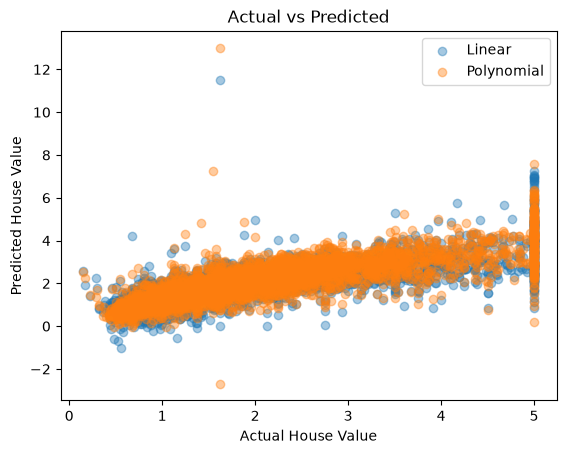

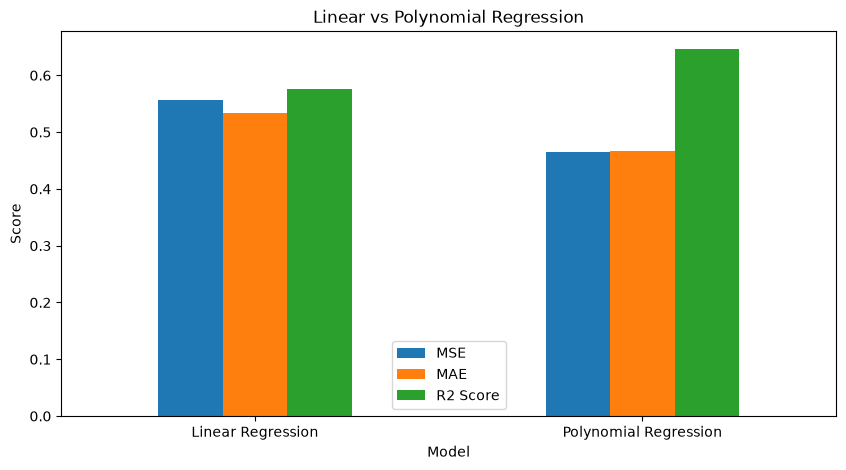

In [14]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# 1. Load Dataset
df = pd.read_csv("fetch_california_housing.csv")

# 2. Correlation Analysis
cor = df.corr(numeric_only=True)

print("Correlation with MedHouseVal:")
print(cor["MedHouseVal"].sort_values(ascending=False))


# 3. Select Input and Target
X = df.drop("MedHouseVal", axis=1)
y = df["MedHouseVal"]

# 4. Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 5. Linear Regression
linear_model = make_pipeline(
    StandardScaler(),
    LinearRegression()
)

linear_model.fit(X_train, y_train)
linear_pred = linear_model.predict(X_test)

# 6. Polynomial Regression
poly_model = make_pipeline(
    StandardScaler(),#StandardScaler is used to bring all features onto a comparable scale.
    PolynomialFeatures(degree=2, include_bias=False),#PolynomialFeatures is used to create new features by combining existing features and adding their powers.
    LinearRegression()
)

poly_model.fit(X_train, y_train)
poly_pred = poly_model.predict(X_test)


# 7. Compare Model Performance
results = pd.DataFrame({
    "Model": ["Linear Regression", "Polynomial Regression"],
    "MSE": [
        mean_squared_error(y_test, linear_pred),
        mean_squared_error(y_test, poly_pred)
    ],
    "MAE": [
        mean_absolute_error(y_test, linear_pred),
        mean_absolute_error(y_test, poly_pred)
    ],
    "R2 Score": [
        r2_score(y_test, linear_pred),
        r2_score(y_test, poly_pred)
    ]
})

print("\nModel Comparison:")
print(results.round(4))

# 8. Actual vs Predicted Graph
plt.scatter(y_test, linear_pred, alpha=0.4, label="Linear")
plt.scatter(y_test, poly_pred, alpha=0.4, label="Polynomial")

plt.xlabel("Actual House Value")
plt.ylabel("Predicted House Value")
plt.title("Actual vs Predicted")
plt.legend()
plt.show()


# Compare MSE, MAE and R2 Score

results.set_index("Model").plot(kind="bar", figsize=(10, 5)) 
plt.title("Linear vs Polynomial Regression") 
plt.ylabel("Score") 
plt.xticks(rotation=0) 
plt.show()

# can remove Performance Comparison Bar Graph Actual vs Predicted scatter plot Feature correlation sortingCorrelation Heatmap
#Correlation Matrix

# Prac 8 - Naive Bayes

Decision Tree Confusion Matrix:
[[ 0  7]
 [ 3 70]]

Naive Bayes Confusion Matrix:
[[ 6  1]
 [13 60]]

Decision Tree Classification Report:
              precision    recall  f1-score   support

           0       0.00      0.00      0.00         7
           1       0.91      0.96      0.93        73

    accuracy                           0.88        80
   macro avg       0.45      0.48      0.47        80
weighted avg       0.83      0.88      0.85        80

Naive Bayes Classification Report:
              precision    recall  f1-score   support

           0       0.32      0.86      0.46         7
           1       0.98      0.82      0.90        73

    accuracy                           0.82        80
   macro avg       0.65      0.84      0.68        80
weighted avg       0.93      0.82      0.86        80


Performance Comparison:
        Model  Accuracy  Precision  Recall  F1-Score
Decision Tree     0.875      0.909   0.959     0.933
  Naive Bayes     0.825      0.984   0.82

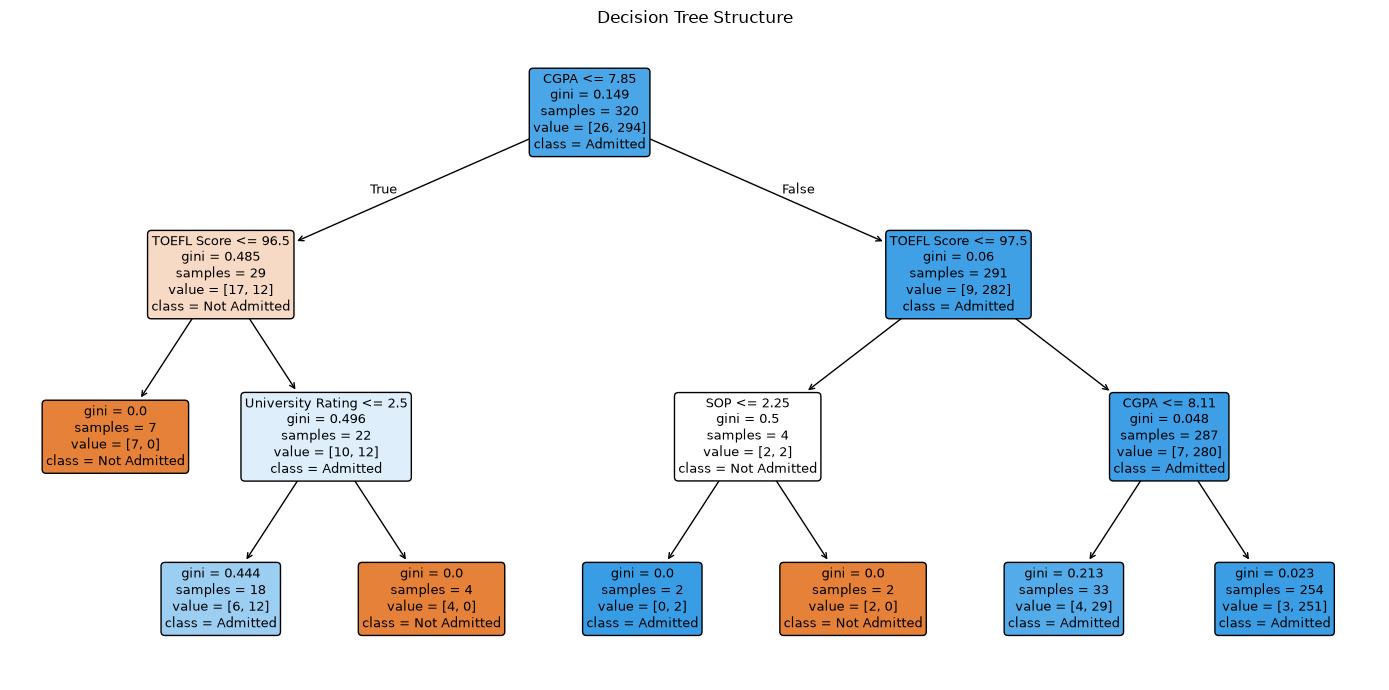

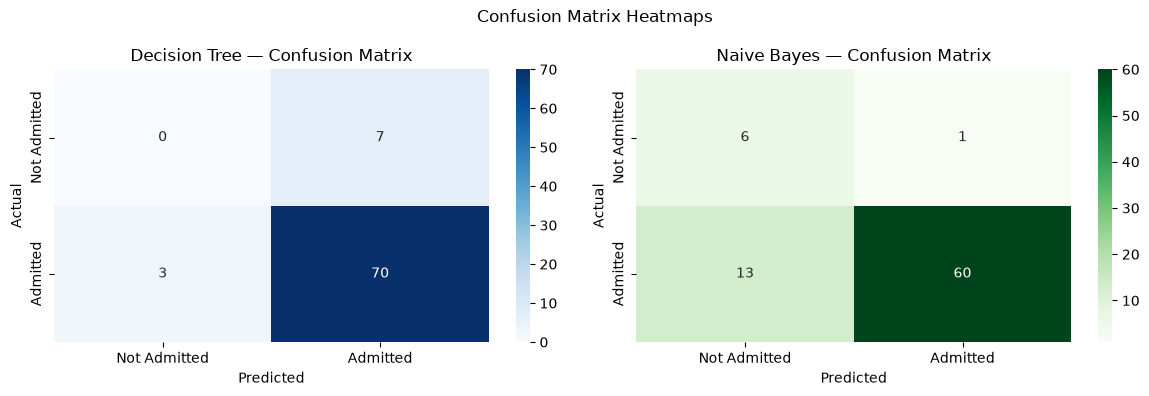

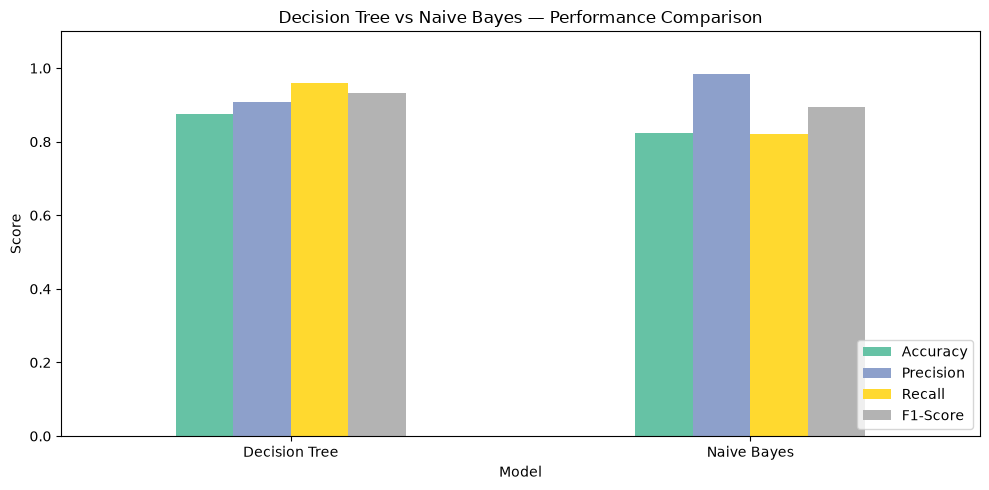

In [8]:
# ============================================================
# AIM: Implement Decision Tree and Naïve Bayes classifiers
#      on a suitable dataset. Compare classifier performance
#      using standard evaluation metrics and identify the
#      most suitable model for the selected dataset.
# ============================================================
#a weak learner is usually a very small Decision Tree
# 1. Import Libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)

# 2. Load Dataset
df = pd.read_csv("Admission_Predict.csv")
df.columns = df.columns.str.strip()
df = df.drop(columns=["Serial No."], errors="ignore")

# 3. Convert Target to Binary Class
df["Admitted"] = (df["Chance of Admit"] >= 0.5).astype(int)#astype gives boolean

# 4. Separate Features and Target
X = df.drop(columns=["Chance of Admit", "Admitted"])
y = df["Admitted"]

# 5. Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 6. Create and Train Models
tree_model = DecisionTreeClassifier(random_state=42, max_depth=3)
nb_model = GaussianNB()

tree_model.fit(X_train, y_train)
nb_model.fit(X_train, y_train)

# 7. Predictions
pred_tree = tree_model.predict(X_test)
pred_nb = nb_model.predict(X_test)

# 8. Confusion Matrices The confusion matrix compares the actual admission status with the predicted admission status.
print("Decision Tree Confusion Matrix:")
print(confusion_matrix(y_test, pred_tree))

print("\nNaive Bayes Confusion Matrix:")
print(confusion_matrix(y_test, pred_nb))

# 9. Classification Reports
print("\nDecision Tree Classification Report:")
print(classification_report(y_test, pred_tree, zero_division=0))

print("Naive Bayes Classification Report:")
print(classification_report(y_test, pred_nb, zero_division=0))

# 10. Performance Comparison
results = pd.DataFrame({
    "Model": ["Decision Tree", "Naive Bayes"],
    "Accuracy": [
        accuracy_score(y_test, pred_tree),
        accuracy_score(y_test, pred_nb)
    ],
    "Precision": [
        precision_score(y_test, pred_tree, zero_division=0),
        precision_score(y_test, pred_nb, zero_division=0)
    ],
    "Recall": [
        recall_score(y_test, pred_tree, zero_division=0),
        recall_score(y_test, pred_nb, zero_division=0)
    ],
    "F1-Score": [
        f1_score(y_test, pred_tree, zero_division=0),
        f1_score(y_test, pred_nb, zero_division=0)
    ]
})

print("\nPerformance Comparison:")
print(results.round(3).to_string(index=False))#means do not display the DataFrame's index numbers when printing the output.

# 11. Identify Most Suitable Model
best_idx = results["F1-Score"].idxmax()#It finds the row index where the F1-Score is highest.
best_model = results.loc[best_idx, "Model"]#is a Pandas function used to access rows and columns of a DataFrame using their labels (names or index labels).
best_f1 = results.loc[best_idx, "F1-Score"]
best_acc = results.loc[best_idx, "Accuracy"]

print("\n" + "="*45)
print("Most Suitable Model  :", best_model)
print("F1-Score             :", round(best_f1, 3))
print("Accuracy             :", round(best_acc, 3))
print("="*45)
#Precision tells us Out of all students predicted as Admitted, how many were actually admitted?
#Out of all students who were actually admitted, how many did our model correctly identify?
# ============================================================
# VISUALIZATIONS bas decision tree bhi bana sakte ho
# ============================================================

# 12. Decision Tree Structure
plt.figure(figsize=(14, 7))
plot_tree(
    tree_model,
    feature_names=X.columns,
    class_names=["Not Admitted", "Admitted"],
    filled=True,
    rounded=True
)
plt.title("Decision Tree Structure")
plt.tight_layout()
plt.show()

# 13. Confusion Matrix Heatmaps
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.heatmap(
    confusion_matrix(y_test, pred_tree),
    annot=True, fmt="d", cmap="Blues",
    xticklabels=["Not Admitted", "Admitted"],
    yticklabels=["Not Admitted", "Admitted"],
    ax=axes[0]
)
axes[0].set_title("Decision Tree — Confusion Matrix")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

sns.heatmap(
    confusion_matrix(y_test, pred_nb),
    annot=True, fmt="d", cmap="Greens",#annot is used to display the numerical values inside each cell of the heatmap. 
    xticklabels=["Not Admitted", "Admitted"],#Displays values as integers fmt
    yticklabels=["Not Admitted", "Admitted"],
    ax=axes[1] #ax=axes[1] is used to specify where the heatmap should be displayed when you have multiple subplots.
)
axes[1].set_title("Naive Bayes — Confusion Matrix")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

plt.suptitle("Confusion Matrix Heatmaps")
plt.tight_layout()
plt.show()

# 14. Performance Comparison Bar Chart
results.set_index("Model").plot(kind="bar", figsize=(10, 5), colormap="Set2")
plt.title("Decision Tree vs Naive Bayes — Performance Comparison")
plt.ylabel("Score")
plt.ylim(0, 1.1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


# can remove Confusion Matrix Heatmaps Performance Comparison Bar Chart
#from section 12 u can remove full till end

# 9 clustering

C:\Users\rishu\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\rishu\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\rishu\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\rishu\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Window

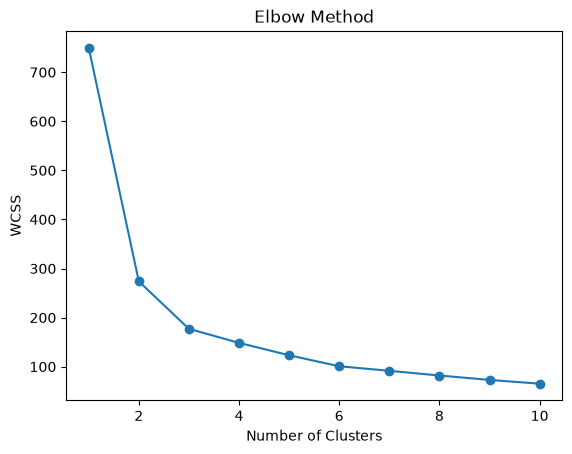

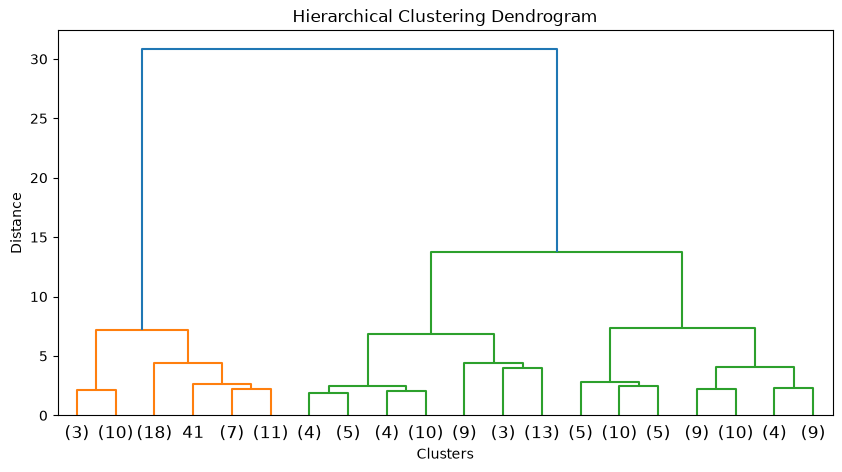

C:\Users\rishu\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


K-Means Cluster Counts:
KMeans_Cluster
0    47
1    53
2    50
Name: count, dtype: int64

Hierarchical Cluster Counts:
Hierarchical_Cluster
0    52
1    50
2    48
Name: count, dtype: int64

K-Means Silhouette Score: 0.453
Hierarchical Silhouette Score: 0.452


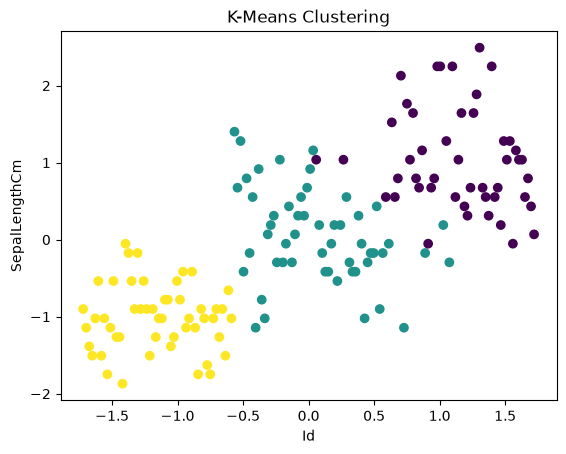


Cluster Assignments:
   Id  SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm      Species  \
0   1            5.1           3.5            1.4           0.2  Iris-setosa   
1   2            4.9           3.0            1.4           0.2  Iris-setosa   
2   3            4.7           3.2            1.3           0.2  Iris-setosa   
3   4            4.6           3.1            1.5           0.2  Iris-setosa   
4   5            5.0           3.6            1.4           0.2  Iris-setosa   

   KMeans_Cluster  Hierarchical_Cluster  
0               2                     1  
1               2                     1  
2               2                     1  
3               2                     1  
4               2                     1  


In [28]:
# ============================================================
# AIM: Implement and compare K-Means and Hierarchical Clustering
# using a suitable dataset.
# ============================================================

# 1. Import Libraries

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import linkage, dendrogram


# 2. Load Iris Dataset

df = pd.read_csv("Iris.csv")

# Remove ID and Species columns
X = df.select_dtypes(include="number")

# select_dtypes(include="number") selects only numerical columns.
# drop() removes unnecessary columns.
# errors="ignore" prevents an error if the column does not exist.


# 3. Feature Scaling

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# StandardScaler converts features to mean=0 and standard deviation=1.
# fit_transform() calculates scaling values and transforms the data.
# Scaling is important because clustering uses distances between points.


# 4. Elbow Method

wcss = []

for k in range(1, 11):

    model = KMeans(n_clusters=k, random_state=42, n_init=10)

    model.fit(X_scaled)

    wcss.append(model.inertia_)

# n_clusters = Number of clusters.
# random_state=42 gives reproducible results.
# n_init=10 runs K-Means 10 times with different initial centroids.
# inertia_ returns WCSS (Within-Cluster Sum of Squares).
# WCSS measures the sum of squared distances from points to centroids.
# Lower WCSS means points are closer to their cluster centers.

plt.plot(range(1, 11), wcss, marker="o")

plt.xlabel("Number of Clusters")
plt.ylabel("WCSS")
plt.title("Elbow Method")
plt.show()

# Elbow Method helps us select the optimal number of clusters.
# We look for the point where WCSS starts decreasing slowly.


# 5. Dendrogram

Z = linkage(X_scaled, method="ward")

# linkage() performs hierarchical clustering.
# method="ward" minimizes the increase in within-cluster variance.
# Z stores the information about cluster merging.

plt.figure(figsize=(10, 5))

dendrogram(Z, truncate_mode="lastp", p=20)

# dendrogram() displays the hierarchical merging process.
# truncate_mode="lastp" displays only the last p merged clusters.
# p=20 limits the displayed branches to 20.

plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Clusters")
plt.ylabel("Distance")
plt.show()

# Dendrogram helps us understand how clusters are merged.
# A large vertical distance suggests a possible cluster separation.


# 6. Apply K-Means Clustering

k = 3

kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)

kmeans_labels = kmeans.fit_predict(X_scaled)

# fit_predict() trains the model and assigns a cluster label to each point.
# Each data point is assigned to one of the 3 clusters.


# 7. Apply Hierarchical Clustering

hierarchical = AgglomerativeClustering(n_clusters=k)

hierarchical_labels = hierarchical.fit_predict(X_scaled)

# AgglomerativeClustering uses a bottom-up approach.
# Initially, every data point is treated as a separate cluster.
# Similar clusters are repeatedly merged.
# fit_predict() returns the cluster labels.


# 8. Analyze Clusters

df["KMeans_Cluster"] = kmeans_labels
df["Hierarchical_Cluster"] = hierarchical_labels

# Adds cluster labels as new columns in the original DataFrame.

print("K-Means Cluster Counts:")

print(df["KMeans_Cluster"].value_counts().sort_index())

# value_counts() counts the number of data points in each cluster.
# sort_index() arranges cluster labels in ascending order.

print("\nHierarchical Cluster Counts:")

print(df["Hierarchical_Cluster"].value_counts().sort_index())


# 9. Calculate Silhouette Score

print("\nK-Means Silhouette Score:",
      round(silhouette_score(X_scaled, kmeans_labels), 3))

print("Hierarchical Silhouette Score:",
      round(silhouette_score(X_scaled, hierarchical_labels), 3))

# Silhouette Score measures how well-separated the clusters are.
# Range: -1 to +1.
# Near +1 = Good clustering.
# Around 0 = Overlapping clusters.
# Negative = Data points may be assigned to the wrong clusters.
# round(..., 3) displays the score up to 3 decimal places.


# 10. Visualize K-Means Clusters

plt.scatter(
    X_scaled[:, 0],  # Selects all rows and first feature.
    X_scaled[:, 1],  # Selects all rows and second feature.
    c=kmeans_labels, # Assigns colors according to cluster labels.
    cmap="viridis"
)

plt.xlabel(X.columns[0])
plt.ylabel(X.columns[1])
plt.title("K-Means Clustering")
plt.show()

# scatter() creates a scatter plot.
# c assigns colors based on cluster labels.
# cmap="viridis" selects the color map.
# This graph displays only the first two features.


# 11. Display Results

print("\nCluster Assignments:")
print(df.head())

# head() displays the first 5 rows with their cluster assignments.


# 12. Save Results

df.to_csv("clustering_results.csv", index=False)

# to_csv() saves the DataFrame as a CSV file.
# index=False prevents Pandas from adding row index numbers.

Dataset:
   Id  SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm      Species
0   1            5.1           3.5            1.4           0.2  Iris-setosa
1   2            4.9           3.0            1.4           0.2  Iris-setosa
2   3            4.7           3.2            1.3           0.2  Iris-setosa
3   4            4.6           3.1            1.5           0.2  Iris-setosa
4   5            5.0           3.6            1.4           0.2  Iris-setosa


C:\Users\rishu\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\rishu\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\rishu\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\rishu\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Window

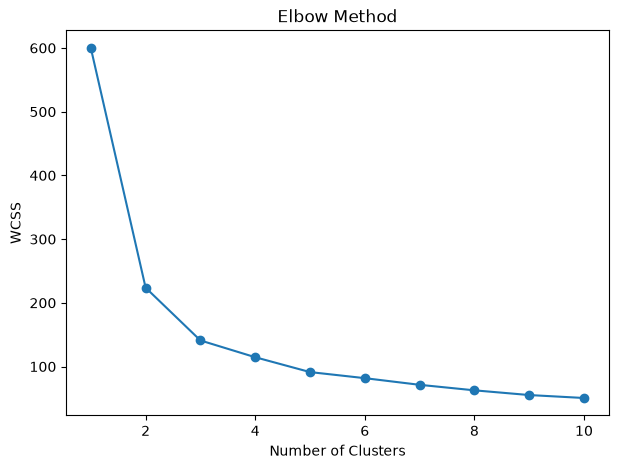

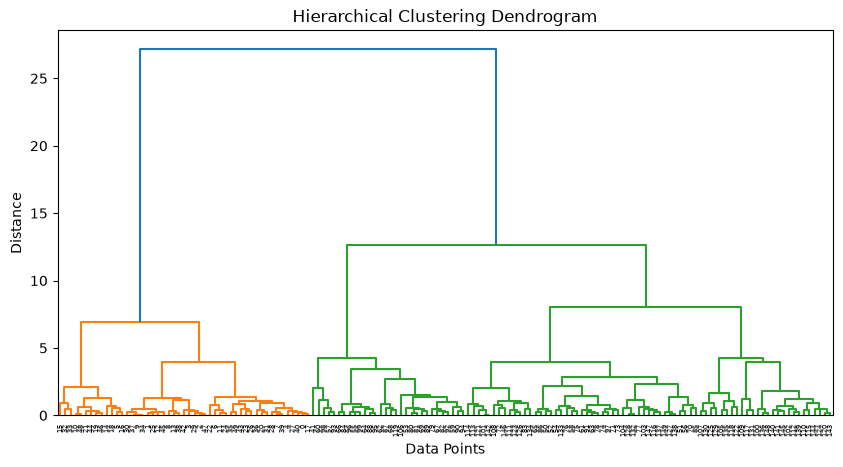

C:\Users\rishu\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(



K-Means Cluster Counts:
KMeans_Cluster
0    53
1    50
2    47
Name: count, dtype: int64

Hierarchical Cluster Counts:
Hierarchical_Cluster
0    71
1    49
2    30
Name: count, dtype: int64

K-Means Silhouette Score: 0.459
Hierarchical Silhouette Score: 0.446


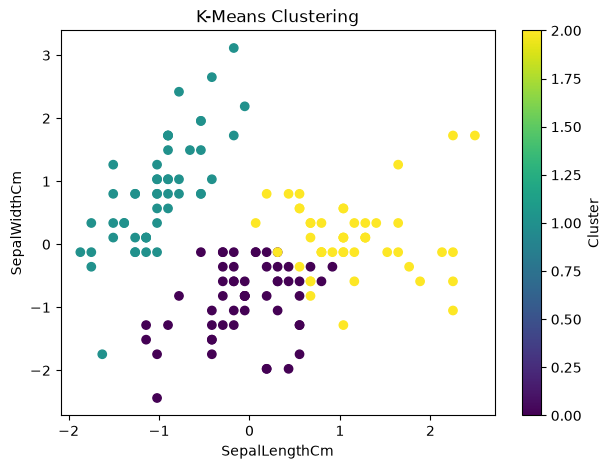

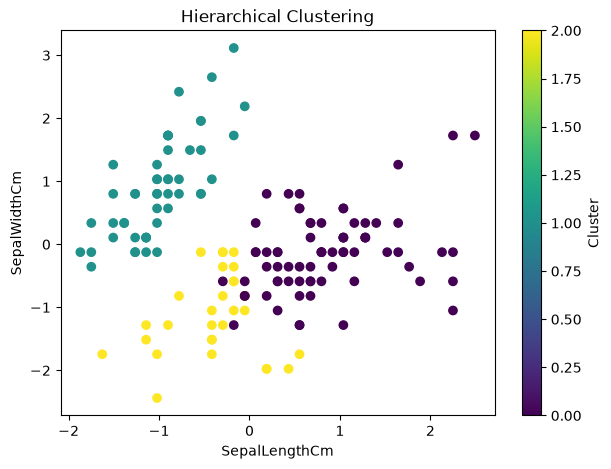


K-Means Cluster vs Actual Species:
Species         Iris-setosa  Iris-versicolor  Iris-virginica
KMeans_Cluster                                              
0                         0               39              14
1                        50                0               0
2                         0               11              36

Hierarchical Cluster vs Actual Species:
Species               Iris-setosa  Iris-versicolor  Iris-virginica
Hierarchical_Cluster                                              
0                               0               23              48
1                              49                0               0
2                               1               27               2


In [29]:
# ============================================================
# AIM: Implement K-Means and Hierarchical Clustering.
# Use Elbow Method and Dendrogram to determine optimal clusters.
# Analyze the generated clusters using Iris dataset.
# ============================================================

# 1. Import Libraries

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import linkage, dendrogram


# 2. Load Dataset

df = pd.read_csv("Iris.csv")

print("Dataset:")
print(df.head())

# head() displays the first 5 rows.
# shape gives the number of rows and columns.


# 3. Separate Features

X = df.drop(columns=["Id", "Species"])

# Id is removed because it is only an identification number.
# Species is removed because clustering is an unsupervised technique.
# X contains the four numerical flower features.


# 4. Feature Scaling

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# StandardScaler converts features to mean=0 and standard deviation=1.
# Scaling is important because clustering uses distance calculations.
# fit_transform() learns scaling values and transforms the data.


# 5. Elbow Method

wcss = []

for k in range(1, 11):

    model = KMeans(n_clusters=k, random_state=42, n_init=10)

    model.fit(X_scaled)

    wcss.append(model.inertia_)

# n_clusters = Number of clusters.
# random_state=42 ensures reproducible results.
# n_init=10 runs K-Means 10 times with different initial centroids.
# inertia_ calculates WCSS (Within-Cluster Sum of Squares).
# WCSS measures the sum of squared distances from points to centroids.

plt.figure(figsize=(7, 5))

plt.plot(range(1, 11), wcss, marker="o")

plt.xlabel("Number of Clusters")
plt.ylabel("WCSS")
plt.title("Elbow Method")
plt.show()

# Elbow Method helps determine the optimal number of clusters.
# We look for the point where WCSS starts decreasing slowly.


# 6. Dendrogram

Z = linkage(X_scaled, method="ward")

# linkage() performs hierarchical clustering.
# method="ward" minimizes the increase in within-cluster variance.
# Z stores information about cluster merging.

plt.figure(figsize=(10, 5))

dendrogram(Z)

plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Data Points")
plt.ylabel("Distance")
plt.show()

# Dendrogram shows how clusters are merged.
# A large vertical gap can indicate a suitable place to cut the tree.
# The number of branches intersected by the cut helps determine clusters.


# 7. Apply K-Means Clustering

k = 3

kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)

kmeans_labels = kmeans.fit_predict(X_scaled)

# fit_predict() trains the model and assigns cluster labels.
# Here, we create 3 clusters based on the Iris dataset.


# 8. Apply Hierarchical Clustering

hierarchical = AgglomerativeClustering(
    n_clusters=k,
    linkage="ward"
)

hierarchical_labels = hierarchical.fit_predict(X_scaled)

# Agglomerative Clustering follows a bottom-up approach.
# Initially, each data point is treated as a separate cluster.
# Similar clusters are repeatedly merged.
# fit_predict() returns the cluster labels.


# 9. Analyze Generated Clusters

df["KMeans_Cluster"] = kmeans_labels
df["Hierarchical_Cluster"] = hierarchical_labels

# Adds cluster assignments to the original dataset.

print("\nK-Means Cluster Counts:")
print(df["KMeans_Cluster"].value_counts().sort_index())

print("\nHierarchical Cluster Counts:")
print(df["Hierarchical_Cluster"].value_counts().sort_index())

# value_counts() counts the number of data points in each cluster.
# sort_index() arranges cluster labels in ascending order.


# 10. Evaluate Clustering

print("\nK-Means Silhouette Score:",
      round(silhouette_score(X_scaled, kmeans_labels), 3))

print("Hierarchical Silhouette Score:",
      round(silhouette_score(X_scaled, hierarchical_labels), 3))

# Silhouette Score measures how well-separated clusters are.
# Range: -1 to +1.
# Near +1 = Good clustering.
# Around 0 = Overlapping clusters.
# Negative = Data points may be assigned to the wrong clusters.


# 11. Visualize K-Means Clusters

plt.figure(figsize=(7, 5))

plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=kmeans_labels,
    cmap="viridis"
)

plt.xlabel(X.columns[0])
plt.ylabel(X.columns[1])
plt.title("K-Means Clustering")
plt.colorbar(label="Cluster")
plt.show()

# X_scaled[:, 0] selects the first feature.
# X_scaled[:, 1] selects the second feature.
# c assigns colors according to cluster labels.
# This graph displays only two features, but clustering uses all four.


# 12. Visualize Hierarchical Clusters

plt.figure(figsize=(7, 5))

plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=hierarchical_labels,
    cmap="viridis"
)

plt.xlabel(X.columns[0])
plt.ylabel(X.columns[1])
plt.title("Hierarchical Clustering")
plt.colorbar(label="Cluster")
plt.show()


# 13. Analyze Clusters Using Actual Species

print("\nK-Means Cluster vs Actual Species:")
print(pd.crosstab(df["KMeans_Cluster"], df["Species"]))

print("\nHierarchical Cluster vs Actual Species:")
print(pd.crosstab(df["Hierarchical_Cluster"], df["Species"]))

# crosstab() compares generated clusters with actual species.
# It helps us understand which flower species are grouped together.
# Species was not used to train either clustering algorithm.


# 14. Save Results

df.to_csv("clustering_results.csv", index=False)

# to_csv() saves the final dataset with cluster assignments.
# index=False prevents additional row index numbers.

# PRAC 10 - PCA

Number of features before PCA: 13
Number of features after PCA: 2

Explained Variance Ratio:
[0.35792104 0.19270671]
Total Variance Retained: 55.06 %


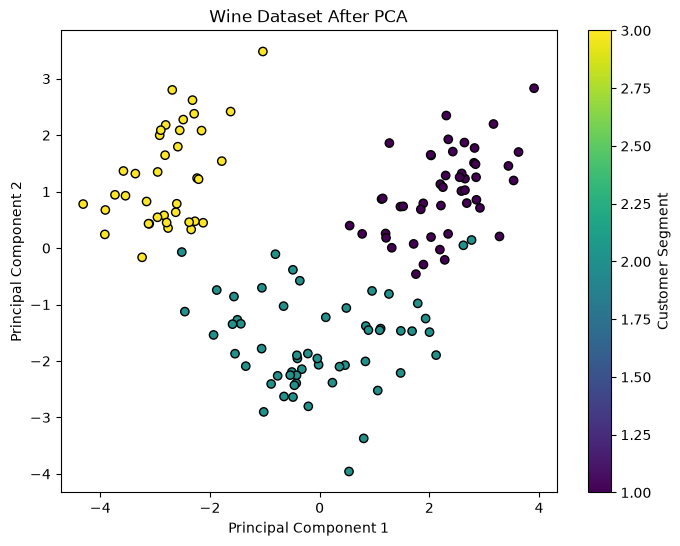


Classification Performance:
 Condition  Features  Accuracy
Before PCA        13     0.972
 After PCA         2     0.917


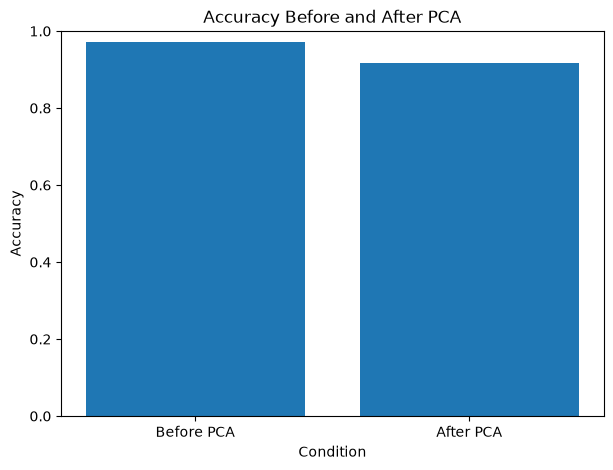

In [9]:
#target wahi jo kam number of values le raha
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

# 1. Load Dataset
df = pd.read_csv("Wine.csv")
#optional hai mun h toh dikhao
# cor = df.corr()['Customer_Segment'].sort_values(ascending=False)
# 2. Separate Features and Target
X = df.drop(columns=["Customer_Segment"])
y = df["Customer_Segment"]

# 3. Split Dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
#We standardize features in PCA because different features have different scales and units.
#Without standardization, features with larger numerical values may dominate PCA
# 4. Standardize Features
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 5. Apply PCA
pca = PCA(n_components=2)

X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

# 6. Compare Number of Features
print("Number of features before PCA:", X.shape[1])
print("Number of features after PCA:", X_train_pca.shape[1])

print("\nExplained Variance Ratio:")
print(pca.explained_variance_ratio_)

print("Total Variance Retained:",
      round(sum(pca.explained_variance_ratio_) * 100, 2), "%")

# 7. Visualize Reduced Dimensions
plt.figure(figsize=(8, 6))

plt.scatter(
    X_train_pca[:, 0],#Selects all rows (:).Selects column 0.Column 0 represents the first principal component (PC1).
    X_train_pca[:, 1],#Selects all rows.Column 1 represents the second principal component (PC2).
    c=y_train,#Each point gets a color based on its target class.
    cmap="viridis",
    edgecolors="black"
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Wine Dataset After PCA")
plt.colorbar(label="Customer Segment")
plt.show()

# 8. Classification Before PCA
model1 = KNeighborsClassifier(n_neighbors=5)
model1.fit(X_train_scaled, y_train)

pred1 = model1.predict(X_test_scaled)
accuracy_before = accuracy_score(y_test, pred1)

# 9. Classification After PCA
model2 = KNeighborsClassifier(n_neighbors=5)
model2.fit(X_train_pca, y_train)

pred2 = model2.predict(X_test_pca)
accuracy_after = accuracy_score(y_test, pred2)

# 10. Compare Classification Performance
results = pd.DataFrame({
    "Condition": ["Before PCA", "After PCA"],
    "Features": [X.shape[1], X_train_pca.shape[1]],
    "Accuracy": [accuracy_before, accuracy_after]
})

print("\nClassification Performance:")
print(results.round(3).to_string(index=False))

# 11. Visualize Accuracy Comparison
plt.figure(figsize=(7, 5))

plt.bar(results["Condition"], results["Accuracy"])

plt.xlabel("Condition")
plt.ylabel("Accuracy")
plt.title("Accuracy Before and After PCA")
plt.ylim(0, 1)
plt.show()
#marzi hai agar karna h toh
# Calculate Covariance Matrix
#cov_matrix = pd.DataFrame(
#    X_train_scaled,
#    columns=X.columns
#).cov()

#print("Covariance Matrix:")
#print(cov_matrix)
#import seaborn as sns

#plt.figure(figsize=(12, 8))
#sns.heatmap(cov_matrix, annot=True, cmap="coolwarm", fmt=".2f")

#plt.title("Covariance Matrix")
#plt.show()

Number of features before PCA: 4
Number of features after PCA: 2

Explained Variance Ratio:
[0.72454871 0.23273095]
Total Variance Retained: 95.73 %


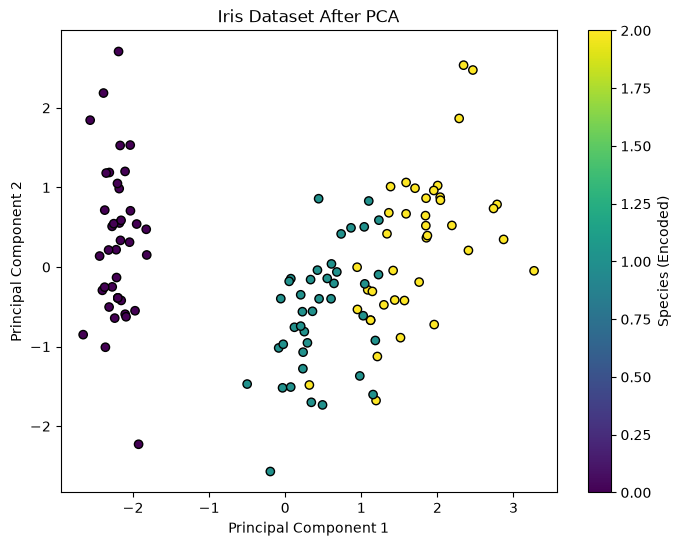


Classification Performance:
 Condition  Features  Accuracy
Before PCA         4     0.933
 After PCA         2     0.900


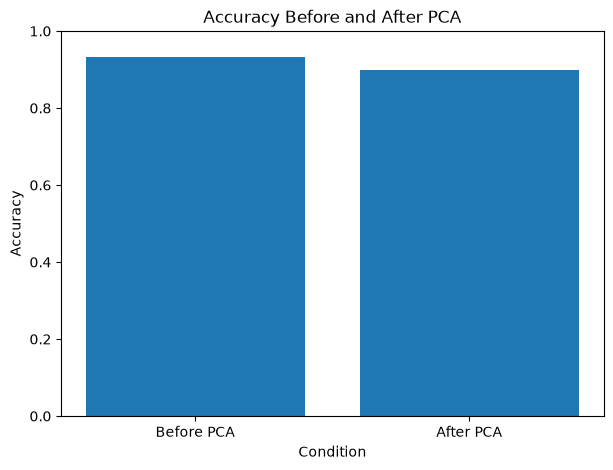

In [23]:
#using iris
# target wahi jo kam number of values le raha
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

# 1. Load Dataset
df = pd.read_csv("Iris.csv")

# Remove ID column because it is not useful for classification
df = df.drop(columns=["Id"])

# optional hai mun h toh dikhao
# cor = df.corr(numeric_only=True)

# 2. Separate Features and Target
X = df.drop(columns=["Species"])
y = df["Species"]

# 3. Split Dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# We standardize features in PCA because different features have different scales and units.
# Without standardization, features with larger numerical values may dominate PCA

# 4. Standardize Features
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 5. Apply PCA
pca = PCA(n_components=2)

X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

# 6. Compare Number of Features
print("Number of features before PCA:", X.shape[1])
print("Number of features after PCA:", X_train_pca.shape[1])

print("\nExplained Variance Ratio:")
print(pca.explained_variance_ratio_)

print("Total Variance Retained:",
      round(sum(pca.explained_variance_ratio_) * 100, 2), "%")

# 7. Visualize Reduced Dimensions
plt.figure(figsize=(8, 6))

plt.scatter(
    X_train_pca[:, 0], # Selects all rows (:). Selects column 0. Column 0 represents the first principal component (PC1).
    X_train_pca[:, 1], # Selects all rows. Column 1 represents the second principal component (PC2).
    c=y_train.astype("category").cat.codes, # Each point gets a color based on its target class.
    cmap="viridis",
    edgecolors="black"
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Iris Dataset After PCA")
plt.colorbar(label="Species (Encoded)")
plt.show()

# 8. Classification Before PCA
model1 = KNeighborsClassifier(n_neighbors=5)
model1.fit(X_train_scaled, y_train)

pred1 = model1.predict(X_test_scaled)
accuracy_before = accuracy_score(y_test, pred1)

# 9. Classification After PCA
model2 = KNeighborsClassifier(n_neighbors=5)
model2.fit(X_train_pca, y_train)

pred2 = model2.predict(X_test_pca)
accuracy_after = accuracy_score(y_test, pred2)

# 10. Compare Classification Performance
results = pd.DataFrame({
    "Condition": ["Before PCA", "After PCA"],
    "Features": [X.shape[1], X_train_pca.shape[1]],
    "Accuracy": [accuracy_before, accuracy_after]
})

print("\nClassification Performance:")
print(results.round(3).to_string(index=False))

# 11. Visualize Accuracy Comparison
plt.figure(figsize=(7, 5))

plt.bar(results["Condition"], results["Accuracy"])

plt.xlabel("Condition")
plt.ylabel("Accuracy")
plt.title("Accuracy Before and After PCA")
plt.ylim(0, 1)
plt.show()

# marzi hai agar karna h toh

# Calculate Covariance Matrix
# cov_matrix = pd.DataFrame(
#     X_train_scaled,
#     columns=X.columns
# ).cov()

# print("Covariance Matrix:")
# print(cov_matrix)

# import seaborn as sns

# plt.figure(figsize=(12, 8))
# sns.heatmap(cov_matrix, annot=True, cmap="coolwarm", fmt=".2f")

# plt.title("Covariance Matrix")
# plt.show()

# prac 11 svm

In [14]:

# Import pandas to load and manipulate the dataset
import pandas as pd

# Import functions for splitting data, cross validation and hyperparameter tuning
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV

# Import StandardScaler to normalize numerical values
from sklearn.preprocessing import StandardScaler

# Import Support Vector Machine classifier
from sklearn.svm import SVC

# Import Random Forest and AdaBoost classification algorithms
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier

# Import make_pipeline to combine preprocessing and machine learning models
from sklearn.pipeline import make_pipeline

# Import evaluation metrics
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score


# 1. LOAD DATASET

# Read CSV file; header=None means the dataset has no column names
df = pd.read_csv("car_evaluation.csv", header=None)

# Assign column names to the dataset
df.columns = ["buying", "maint", "doors", "persons",
              "lug_boot", "safety", "class"]


# 2. SEPARATE INPUT AND OUTPUT

# Convert categorical input columns into numerical dummy variables (0 and 1)
# Drop class because it is the target/output column
X = pd.get_dummies(df.drop("class", axis=1))

# Convert target class labels into numerical codes
y = df["class"].astype("category").cat.codes


# 3. SPLIT DATASET

# Split data into training (80%) and testing (20%) sets
# random_state=42 ensures the same split every time
# stratify=y maintains the same class distribution in both sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)


# 4. CREATE MODELS

models = {

    # StandardScaler normalizes features before applying SVM
    # SVC() creates the Support Vector Machine classifier
    "SVM": make_pipeline(StandardScaler(), SVC()),

    # Random Forest combines multiple decision trees
    # random_state ensures reproducible results
    "Random Forest": RandomForestClassifier(random_state=42),

    # AdaBoost combines weak learners to create a stronger model
    "AdaBoost": AdaBoostClassifier(random_state=42)
}


# 5. HYPERPARAMETERS FOR GRID SEARCH

params = {

    # SVM hyperparameters
    "SVM": {
        "svc__C": [1, 10],           # Controls penalty for classification errors
        "svc__kernel": ["linear", "rbf"]  # Type of decision boundary
    },

    # Random Forest hyperparameters
    "Random Forest": {
        "n_estimators": [50, 100],   # Number of decision trees
        "max_depth": [None, 10]      # Maximum depth of each tree
    },
    #we create decision tree stump and choose the best stump trees with level 1 only is called decision tree stump
    #a weak learner is usually a very small Decision Tree then we make took sample width which is probability of selecting that row from total no. of r
    #sum of total errors and performance of stomp
    #sum of total error for each stomp
    #performance stomp = 1/2ln[1-te/te]
    #fxn = alpha1(ofM1)+same for 2...... alpha is performance stomp
    #increase weight of wrong classified
    #we add updated weights for correctly classified points (accuracy is correct)=weight *e^-performance of stomp for wrong =  weight*e^performance stomp
    #normalize weight = row ka current updated w8/total w8 of the updated w8 galat wale ka jada hoga value
    #bin assignment 0 to normalized wt of first row,first row to (first+2nd ka),1+2ka ,1+2+3 ka galat wale ka jada hoga range
    #agar ab for loop lagaenge toh yeh range mai woh model jada aaega and we know woh galat hai toh woh next model ko train krne mai help karega
    #he data points given more importance to the next Decision Stump are the points that the previous stump predicted incorrectly.
    #calculate yes and no performance by adding all alpha of yes and adding of all alpha of no
    # AdaBoost hyperparameters
    "AdaBoost": {
        "n_estimators": [50, 100],   # Number of weak learners
        "learning_rate": [0.5, 1]    # Controls the contribution of each learner
    }
}


# 6. TRAIN, CROSS VALIDATE AND OPTIMIZE

# Loop through all three machine learning models
for name, model in models.items():

    # BEFORE OPTIMIZATION

    # Train the model using training data
    model.fit(X_train, y_train)

    # Predict output for testing data
    pred_before = model.predict(X_test)

    # Calculate accuracy before hyperparameter tuning
    before = accuracy_score(y_test, pred_before)


    # CROSS VALIDATION

    # Divide training data into 3 folds
    # Train on 2 folds and validate on 1 fold
    # Repeat 3 times and calculate average accuracy
    cv = cross_val_score(model, X_train, y_train, cv=3).mean()


    # GRID SEARCH
    #A hyperparameter is a setting that we decide before training a machine learning model.It controls how the model learns from the data.
    #GridSearchCV stands for Grid Search Cross-Validation.

#It is used to find the best combination of hyperparameters for a machine learning model.

#In simple words:

#GridSearchCV tries different combinations of hyperparameter values, checks their performance using cross-validation, and selects the best combination.

#How does GridSearchCV work?

#Step 1: Select a machine learning model.

#Step 2: Define different hyperparameter values to test.

#Step 3: GridSearchCV creates all possible combinations.

#Step 4: It trains and evaluates the model using cross-validation for each combination.

#Step 5: It compares the results.

#Step 6: It selects the combination with the best performance.
    #train several models
    #cv basically single row ya column mai lagta hai  1 ke neeche sabko lete h and in grid 2 one column ki 2 next column ki to get 
    #now we can swap these to get max validation score keeping some fixed hyperparamaters and other we can change we get max we select
    # Try different combinations of hyperparameters
    # cv=3 means 3-fold cross validation
    # scoring="accuracy" selects the combination with the highest accuracy
    grid = GridSearchCV(model, params[name], cv=3, scoring="accuracy")

    # Perform hyperparameter tuning on training data
    grid.fit(X_train, y_train)


    # AFTER OPTIMIZATION

    # Get the model with the best hyperparameter combination
    best_model = grid.best_estimator_

    # Predict using the optimized model
    pred_after = best_model.predict(X_test)

    # Calculate accuracy after optimization
    after = accuracy_score(y_test, pred_after)


    # DISPLAY RESULTS

    print("\n", name)

    # Accuracy before hyperparameter optimization
    print("Before Optimization:", round(before, 4))

    # Average accuracy obtained through cross validation
    print("Cross Validation:", round(cv, 4))

    # Display the best hyperparameters found by Grid Search
    print("Best Parameters:", grid.best_params_)

    # Accuracy after hyperparameter optimization
    print("After Optimization:", round(after, 4))

    # Precision: How many predicted positive results were actually positive
    print("Precision:", round(precision_score(
        y_test, pred_after, average="weighted"), 4))

    # Recall: How many actual positive results were correctly identified
    print("Recall:", round(recall_score(
        y_test, pred_after, average="weighted"), 4))

    # F1-score: Harmonic mean of precision and recall
    print("F1-Score:", round(f1_score(
        y_test, pred_after, average="weighted"), 4))

#It is a supervised machine learning algorithm mainly used for classification. It can also be used for regression.
#Random Forest is a supervised machine learning algorithm used for both classification and regression.

#random forest It combines multiple Decision Trees to make a final prediction.
#it creates multiple random samples from the training dataset.
#It trains a separate Decision Tree on each sample.
#Each tree makes its own prediction.
#All predictions are combined to get the final result.


#AdaBoost is a supervised machine learning algorithm mainly used for classification. It can also be used for regression through variants such as AdaBoost Regressor.

#It combines multiple weak learners to create a strong learner.

#A weak learner is a simple model that performs slightly better than random guessing.

#In AdaBoost, a small Decision Tree with only one level is commonly used as a weak learner. It is called a Decision Stump.

#How does it work?

#AdaBoost starts with equal weights for all training data points.
#The first Decision Stump makes predictions.
#It identifies incorrectly classified data points.
#It increases the weights of incorrectly classified points.
#It trains the next Decision Stump using the updated weights.
#This process continues with multiple weak learners.
#Finally, all weak learners are combined using weighted voting to make the final prediction.



#Hyperparameter tuning is a crucial step in machine learning to find the best set of hyperparameters for a model.

#Hyperparameters are settings that are not learned from the data during training, 
#but they determine how a machine learning algorithm learns from the data.



 SVM
Before Optimization: 0.974
Cross Validation: 0.9508
Best Parameters: {'svc__C': 10, 'svc__kernel': 'rbf'}
After Optimization: 0.9971
Precision: 0.9971
Recall: 0.9971
F1-Score: 0.9971

 Random Forest
Before Optimization: 0.9682
Cross Validation: 0.9479
Best Parameters: {'max_depth': None, 'n_estimators': 100}
After Optimization: 0.9682
Precision: 0.9688
Recall: 0.9682
F1-Score: 0.9678

 AdaBoost
Before Optimization: 0.8439
Cross Validation: 0.8423
Best Parameters: {'learning_rate': 1, 'n_estimators': 100}
After Optimization: 0.8584
Precision: 0.8894
Recall: 0.8584
F1-Score: 0.8525


In [24]:
# ============================================================
# AIM: Compare SVM, Random Forest and AdaBoost using
# Cross Validation and Grid Search.
# ============================================================

# 1. Import Libraries
import pandas as pd

from sklearn.model_selection import train_test_split, cross_validate, GridSearchCV
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# 2. Load Dataset
df = pd.read_csv("car_evaluation.csv", header=None,
                 names=["buying", "maint", "doors", "persons",
                        "lug_boot", "safety", "class"])

# 3. Separate Features and Target
X = df.drop(columns=["class"])
y = df["class"]

# 4. Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 5. Encode Categorical Features
preprocessor = ColumnTransformer([
    ("encoder", OneHotEncoder(handle_unknown="ignore"), X.columns)
])

# 6. Create Models
models = {
    "SVM": SVC(),
    "Random Forest": RandomForestClassifier(random_state=42),
    "AdaBoost": AdaBoostClassifier(random_state=42)
}

# 7. Hyperparameter Grids
params = {
    "SVM": {
        "model__C": [0.1, 1, 10],
        "model__kernel": ["linear", "rbf"]
    },

    "Random Forest": {
        "model__n_estimators": [50, 100],
        "model__max_depth": [None, 10]
    },

    "AdaBoost": {
        "model__n_estimators": [50, 100],
        "model__learning_rate": [0.1, 1.0]
    }
}

# 8. Cross Validation and Performance Comparison
before = []
after = []

for name, model in models.items():

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    # Cross Validation
    cv_result = cross_validate(
        pipeline, X_train, y_train, cv=5,
        scoring="accuracy"
    )

    print("\n", name, "CV Accuracy:", round(cv_result["test_score"].mean(), 3))

    # Before Optimization
    pipeline.fit(X_train, y_train)
    pred = pipeline.predict(X_test)

    before.append([
        name,
        accuracy_score(y_test, pred),
        precision_score(y_test, pred, average="weighted", zero_division=0),
        recall_score(y_test, pred, average="weighted", zero_division=0),
        f1_score(y_test, pred, average="weighted", zero_division=0)
    ])

    # Grid Search
    grid = GridSearchCV(
        pipeline, params[name], cv=5,
        scoring="f1_weighted", n_jobs=-1
    )

    grid.fit(X_train, y_train)

    # After Optimization
    pred = grid.best_estimator_.predict(X_test)

    after.append([
        name,
        accuracy_score(y_test, pred),
        precision_score(y_test, pred, average="weighted", zero_division=0),
        recall_score(y_test, pred, average="weighted", zero_division=0),
        f1_score(y_test, pred, average="weighted", zero_division=0)
    ])

    print("Best Parameters:", grid.best_params_)

# 9. Display Results
columns = ["Model", "Accuracy", "Precision", "Recall", "F1-Score"]

before_df = pd.DataFrame(before, columns=columns)
after_df = pd.DataFrame(after, columns=columns)

print("\nPerformance Before Optimization:")
print(before_df.round(3).to_string(index=False))

print("\nPerformance After Optimization:")
print(after_df.round(3).to_string(index=False))

# 10. Final Comparison
comparison = pd.DataFrame({
    "Model": before_df["Model"],
    "Before Accuracy": before_df["Accuracy"],
    "After Accuracy": after_df["Accuracy"],
    "Before F1": before_df["F1-Score"],
    "After F1": after_df["F1-Score"]
})

print("\nFinal Comparison:")
print(comparison.round(3).to_string(index=False))

# 11. Best Model
best_idx = after_df["F1-Score"].idxmax()

print("\nBest Model:", after_df.loc[best_idx, "Model"])
print("Best F1-Score:", round(after_df.loc[best_idx, "F1-Score"], 3))


 SVM CV Accuracy: 0.955
Best Parameters: {'model__C': 10, 'model__kernel': 'rbf'}

 Random Forest CV Accuracy: 0.945
Best Parameters: {'model__max_depth': None, 'model__n_estimators': 50}

 AdaBoost CV Accuracy: 0.838
Best Parameters: {'model__learning_rate': 1.0, 'model__n_estimators': 100}

Performance Before Optimization:
        Model  Accuracy  Precision  Recall  F1-Score
          SVM     0.974      0.975   0.974     0.974
Random Forest     0.968      0.969   0.968     0.968
     AdaBoost     0.844      0.855   0.844     0.839

Performance After Optimization:
        Model  Accuracy  Precision  Recall  F1-Score
          SVM     1.000      1.000   1.000     1.000
Random Forest     0.971      0.972   0.971     0.971
     AdaBoost     0.858      0.889   0.858     0.852

Final Comparison:
        Model  Before Accuracy  After Accuracy  Before F1  After F1
          SVM            0.974           1.000      0.974     1.000
Random Forest            0.968           0.971      0.968   

Dataset:
  buying  maint doors persons lug_boot safety  class
0  vhigh  vhigh     2       2    small    low  unacc
1  vhigh  vhigh     2       2    small    med  unacc
2  vhigh  vhigh     2       2    small   high  unacc
3  vhigh  vhigh     2       2      med    low  unacc
4  vhigh  vhigh     2       2      med    med  unacc

 SVM
CV Accuracy: 0.955
Best Parameters: {'model__C': 10, 'model__kernel': 'rbf'}

 Random Forest
CV Accuracy: 0.945
Best Parameters: {'model__max_depth': None, 'model__n_estimators': 50}

 AdaBoost
CV Accuracy: 0.838
Best Parameters: {'model__learning_rate': 1.0, 'model__n_estimators': 100}

Performance Before Optimization:
        Model  Accuracy  Precision  Recall  F1-Score
          SVM     0.974      0.975   0.974     0.974
Random Forest     0.968      0.969   0.968     0.968
     AdaBoost     0.844      0.855   0.844     0.839

Performance After Optimization:
        Model  Accuracy  Precision  Recall  F1-Score
          SVM     1.000      1.000   1.000     

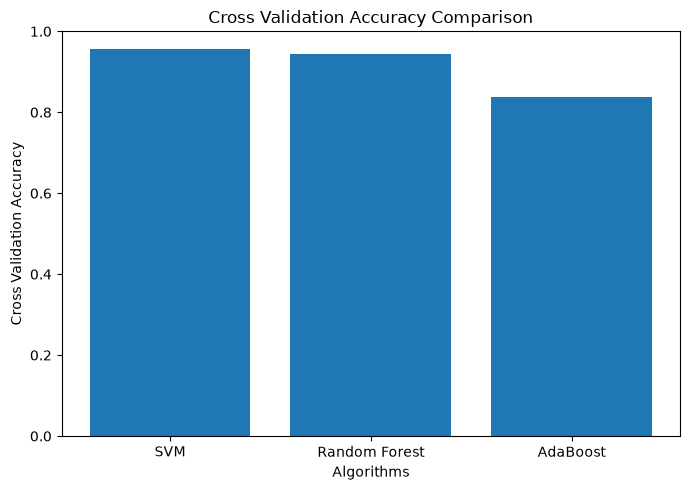

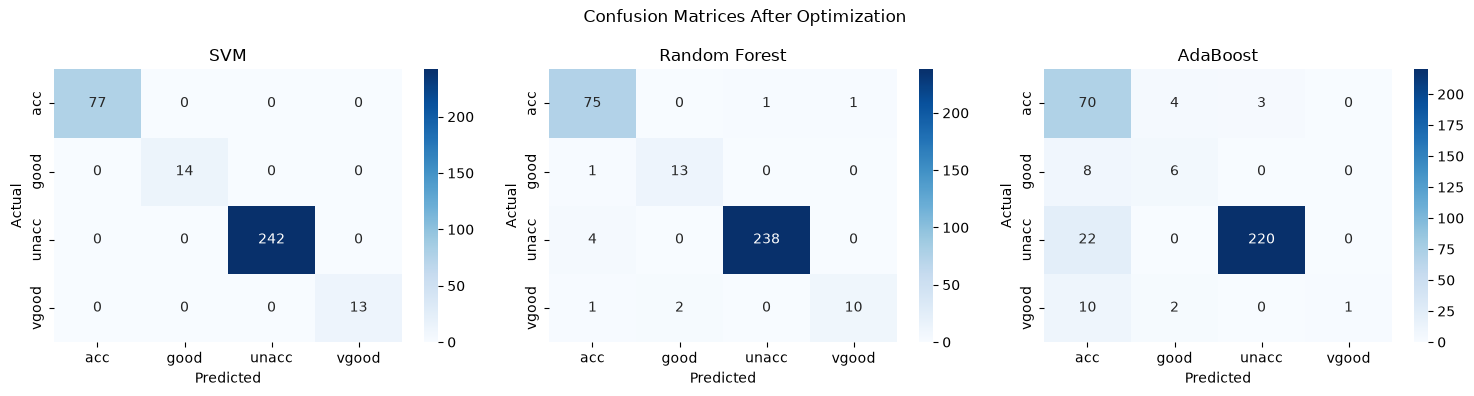

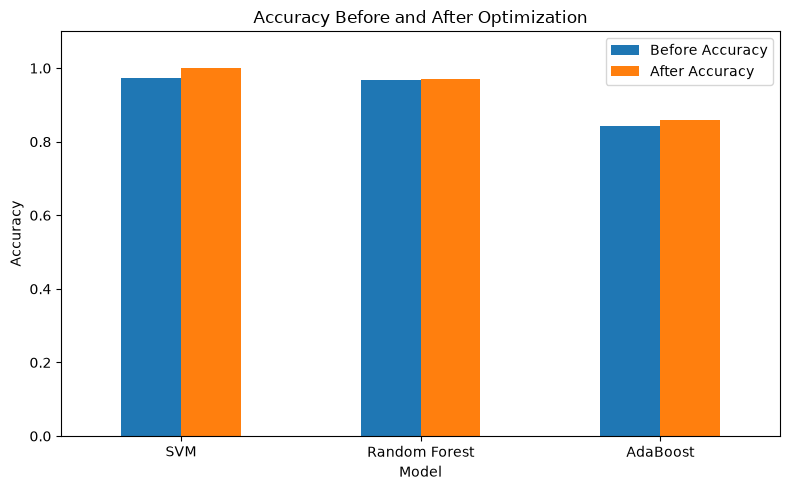

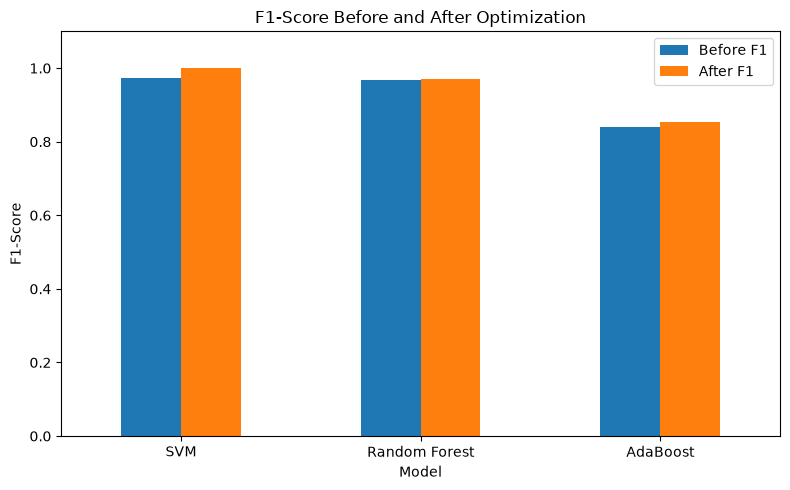

In [25]:
# ============================================================
# AIM: Compare SVM, Random Forest and AdaBoost using
# Cross Validation and Grid Search.
# ============================================================

# 1. Import Libraries

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_validate, GridSearchCV
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix
)


# 2. Load Dataset

df = pd.read_csv(
    "car_evaluation.csv",
    header=None,
    names=["buying", "maint", "doors", "persons",
           "lug_boot", "safety", "class"]
)

print("Dataset:")
print(df.head())

# head() displays the first 5 rows.
# shape gives the number of rows and columns.


# 3. Separate Features and Target

X = df.drop(columns=["class"])
y = df["class"]

# X contains input features.
# y contains the target/output column.


# 4. Train-Test Split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# test_size=0.2 means 20% testing and 80% training.
# random_state=42 ensures reproducible splitting.
# stratify=y maintains class proportions in both sets.


# 5. Encode Categorical Features

preprocessor = ColumnTransformer([
    ("encoder", OneHotEncoder(handle_unknown="ignore"), X.columns)
])

# OneHotEncoder converts categorical values into numerical columns.
# handle_unknown="ignore" handles categories not seen during training.
# ColumnTransformer applies encoding to the selected columns.


# 6. Create Models

models = {
    "SVM": SVC(),
    "Random Forest": RandomForestClassifier(random_state=42),
    "AdaBoost": AdaBoostClassifier(random_state=42)
}

# SVM finds an optimal separating boundary.
# Random Forest combines multiple decision trees.
# AdaBoost combines weak learners to create a stronger model.


# 7. Hyperparameter Grids

params = {
    "SVM": {
        "model__C": [0.1, 1, 10],
        "model__kernel": ["linear", "rbf"]
    },

    "Random Forest": {
        "model__n_estimators": [50, 100],
        "model__max_depth": [None, 10]
    },

    "AdaBoost": {
        "model__n_estimators": [50, 100],
        "model__learning_rate": [0.1, 1.0]
    }
}

# C = Controls penalty for misclassification in SVM.
# kernel = Defines the type of decision boundary.
# n_estimators = Number of trees/weak learners.
# max_depth = Maximum depth of a decision tree.
# learning_rate = Controls the contribution of each weak learner.

# model__ is used because the model is inside a Pipeline.
# Double underscore accesses parameters of a pipeline step.


# 8. Cross Validation and Performance Comparison

before = []
after = []
cv_scores = []
best_models = {}

for name, model in models.items():

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    # Pipeline combines preprocessing and model training.

    # Cross Validation
    cv_result = cross_validate(
        pipeline, X_train, y_train, cv=5,
        scoring="accuracy"
    )

    cv_accuracy = cv_result["test_score"].mean()
    cv_scores.append([name, cv_accuracy])

    print("\n", name)
    print("CV Accuracy:", round(cv_accuracy, 3))

    # cv=5 divides training data into 5 folds.
    # Each fold gets a turn as validation data.
    # mean() calculates the average validation accuracy.

    # Before Optimization
    pipeline.fit(X_train, y_train)

    pred = pipeline.predict(X_test)

    before.append([
        name,
        accuracy_score(y_test, pred),
        precision_score(y_test, pred, average="weighted", zero_division=0),
        recall_score(y_test, pred, average="weighted", zero_division=0),
        f1_score(y_test, pred, average="weighted", zero_division=0)
    ])

    # fit() trains the model.
    # predict() predicts the output for test data.

    # Grid Search
    grid = GridSearchCV(
        pipeline, params[name], cv=5,
        scoring="f1_weighted", n_jobs=-1
    )

    grid.fit(X_train, y_train)

    # GridSearchCV tests different parameter combinations.
    # scoring="f1_weighted" selects the best parameters using weighted F1.
    # n_jobs=-1 uses all available CPU cores.

    # After Optimization
    best_model = grid.best_estimator_
    best_models[name] = best_model

    pred = best_model.predict(X_test)

    after.append([
        name,
        accuracy_score(y_test, pred),
        precision_score(y_test, pred, average="weighted", zero_division=0),
        recall_score(y_test, pred, average="weighted", zero_division=0),
        f1_score(y_test, pred, average="weighted", zero_division=0)
    ])

    print("Best Parameters:", grid.best_params_)


# 9. Display Results

columns = ["Model", "Accuracy", "Precision", "Recall", "F1-Score"]

before_df = pd.DataFrame(before, columns=columns)
after_df = pd.DataFrame(after, columns=columns)

print("\nPerformance Before Optimization:")
print(before_df.round(3).to_string(index=False))

print("\nPerformance After Optimization:")
print(after_df.round(3).to_string(index=False))

# round(3) displays values up to 3 decimal places.
# to_string(index=False) displays the table without row numbers.


# 10. Final Comparison

comparison = pd.DataFrame({
    "Model": before_df["Model"],
    "Before Accuracy": before_df["Accuracy"],
    "After Accuracy": after_df["Accuracy"],
    "Before F1": before_df["F1-Score"],
    "After F1": after_df["F1-Score"]
})

print("\nFinal Comparison:")
print(comparison.round(3).to_string(index=False))


# 11. Best Model

best_idx = after_df["F1-Score"].idxmax()

best_model = after_df.loc[best_idx, "Model"]
best_f1 = after_df.loc[best_idx, "F1-Score"]

print("\nBest Model:", best_model)
print("Best F1-Score:", round(best_f1, 3))

# idxmax() returns the index of the maximum value.
# loc[] accesses a particular row and column using labels.


# ============================================================
# 12. VISUALIZATIONS
# ============================================================


# GRAPH 1: Cross Validation Accuracy Comparison

cv_df = pd.DataFrame(cv_scores, columns=["Model", "CV Accuracy"])

plt.figure(figsize=(7, 5))

plt.bar(cv_df["Model"], cv_df["CV Accuracy"])

plt.xlabel("Algorithms")
plt.ylabel("Cross Validation Accuracy")
plt.title("Cross Validation Accuracy Comparison")
plt.ylim(0, 1)

plt.tight_layout()
plt.show()


# GRAPH 2: Confusion Matrix of Optimized Models

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (name, model) in zip(axes, best_models.items()):

    pred = model.predict(X_test)

    cm = confusion_matrix(y_test, pred, labels=model.classes_)

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=model.classes_,
        yticklabels=model.classes_,
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.suptitle("Confusion Matrices After Optimization")
plt.tight_layout()
plt.show()


# GRAPH 3: Before vs After Optimization

comparison.set_index("Model")[
    ["Before Accuracy", "After Accuracy"]
].plot(kind="bar", figsize=(8, 5))

plt.title("Accuracy Before and After Optimization")
plt.ylabel("Accuracy")
plt.ylim(0, 1.1)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


# GRAPH 4: F1-Score Comparison

comparison.set_index("Model")[
    ["Before F1", "After F1"]
].plot(kind="bar", figsize=(8, 5))

plt.title("F1-Score Before and After Optimization")
plt.ylabel("F1-Score")
plt.ylim(0, 1.1)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# himanshu

In [ ]:
#6
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
df = pd.read_csv("california_housing.csv")

X = df.drop("MedHouseVal", axis=1)
y = df["MedHouseVal"]

X_train, X_test, y_train,y_test = train_test_split(X,y, test_size=0.2,random_state=42)

linear_model = make_pipeline(StandardScaler(), LinearRegression())
linear_model.fit(X_train, y_train)
linear_pred = linear_model.predict(X_test)

polynomail_model = make_pipeline(StandardScaler(), PolynomialFeatures(degree=2, include_bias=False), LinearRegression())
polynomail_model.fit(X_train, y_train)
polynomial_pred = polynomail_model.predict(X_test)

result = pd.DataFrame({
    "Models": ["Linear Regression", "Polynomial Regression"],
    "MSE": [mean_squared_error(y_test, linear_pred), mean_squared_error(y_test, polynomial_pred)],
    "MAE": [mean_absoluteError(y_test, linear_pred), mean_absolute_error(y_test, polynomial_pred)],
    "R2 Score": [r2_score(y_test, linear_pred), r2_score]
})

print(result.round(4));

plt.scatter(y_test, linear_pred, color='blue', label='Linear Regression')
plt.scatter(y_test, polynomial_pred, color='red', label='Polynomial Regression')
plt.xlabel('Actual Values')
plt.ylabel('Predicted Values')
plt.title('Actual vs Predicted Values')
plt.legend()
plt.show()

In [ ]:
#11
import pandas as pd
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score

# 1. Load dataset
df = pd.read_csv("car_evaluation.csv", header=None)

df.columns = ["buying", "maint", "doors", "persons",
              "lug_boot", "safety", "class"]

# 2. Separate input and output
X = pd.get_dummies(df.drop("class", axis=1))
y = df["class"].astype("category").cat.codes

# 3. Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 4. Create models
models = {
    "SVM": make_pipeline(StandardScaler(), SVC()),
    "Random Forest": RandomForestClassifier(random_state=42),
    "AdaBoost": AdaBoostClassifier(random_state=42)
}

# 5. Hyperparameters for Grid Search
params = {
    "SVM": {
        "svc__C": [1, 10],
        "svc__kernel": ["linear", "rbf"]
    },
    "Random Forest": {
        "n_estimators": [50, 100],
        "max_depth": [None, 10]
    },
    "AdaBoost": {
        "n_estimators": [50, 100],
        "learning_rate": [0.5, 1]
    }
}

# 6. Train, Cross Validate and Optimize
for name, model in models.items():

    # Before optimization
    model.fit(X_train, y_train)
    before = accuracy_score(y_test, model.predict(X_test))

    # Cross Validation
    cv = cross_val_score(model, X_train, y_train, cv=3).mean()
    #training dataset is divided 2 are trained and one is used for validation

    # Grid Search
    grid = GridSearchCV(model, params[name], cv=3)
    grid.fit(X_train, y_train)

    # After optimization
    after = accuracy_score(y_test, grid.best_estimator_.predict(X_test))

    print("\n", name)
    print("Before Optimization:", round(before, 4))
    print("Cross Validation:", round(cv, 4))
    print("Best Parameters:", grid.best_params_)
    print("After Optimization:", round(after, 4))

In [ ]:
#10
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

# Load Wine dataset
df = pd.read_csv("Wine.csv")

X = df.drop("Customer_Segment", axis=1)
y = df["Customer_Segment"]

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Standardize the data
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# KNN before PCA
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)
acc_before = accuracy_score(y_test, knn.predict(X_test))

# Apply PCA (retain 95% variance)
pca = PCA(n_components=0.95)
X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test)

# KNN after PCA
knn.fit(X_train_pca, y_train)
acc_after = accuracy_score(y_test, knn.predict(X_test_pca))

# Display results
print("Features before PCA:", X_train.shape[1])
print("Features after PCA:", X_train_pca.shape[1])
print("Accuracy before PCA:", round(acc_before * 100, 2), "%")
print("Accuracy after PCA:", round(acc_after * 100, 2), "%")
print("Variance retained:",
      round(pca.explained_variance_ratio_.sum() * 100, 2), "%")

# Visualize reduced dimensions
pca_2d = PCA(n_components=2)
X_scaled = scaler.transform(X)
X_2d = pca_2d.fit_transform(X_scaled)

plt.scatter(X_2d[:, 0], X_2d[:, 1], c=y, cmap="viridis")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Wine Dataset PCA Visualization")
plt.colorbar(label="Customer Segment")
plt.show()

C:\Users\rishu\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\rishu\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\rishu\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\rishu\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Window

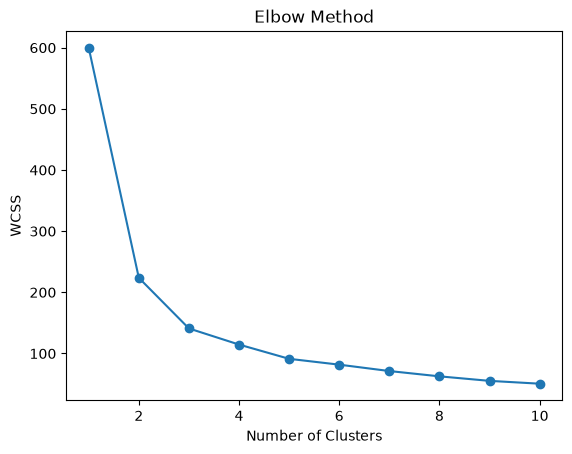

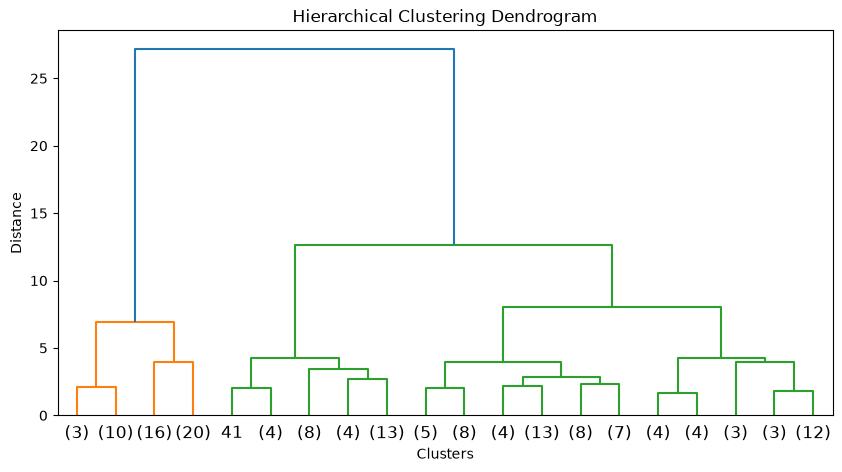

C:\Users\rishu\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


K-Means Cluster Counts:
KMeans_Cluster
0    53
1    50
2    47
Name: count, dtype: int64

Hierarchical Cluster Counts:
Hierarchical_Cluster
0    71
1    49
2    30
Name: count, dtype: int64

K-Means Silhouette Score: 0.459
Hierarchical Silhouette Score: 0.446


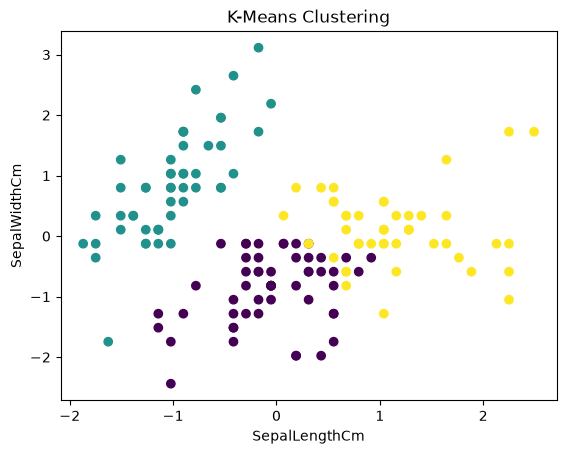


Cluster Assignments:
   Id  SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm      Species  \
0   1            5.1           3.5            1.4           0.2  Iris-setosa   
1   2            4.9           3.0            1.4           0.2  Iris-setosa   
2   3            4.7           3.2            1.3           0.2  Iris-setosa   
3   4            4.6           3.1            1.5           0.2  Iris-setosa   
4   5            5.0           3.6            1.4           0.2  Iris-setosa   

   KMeans_Cluster  Hierarchical_Cluster  
0               1                     1  
1               1                     1  
2               1                     1  
3               1                     1  
4               1                     1  


In [15]:
#9

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import linkage, dendrogram

# 1. Load Iris dataset
df = pd.read_csv("Iris.csv")

# Remove ID and Species columns
X = df.select_dtypes(include="number")
X = X.drop(columns=["Id", "id"], errors="ignore")

# 2. Feature scaling
X_scaled = StandardScaler().fit_transform(X)

# 3. Elbow Method
wcss = []

for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X_scaled)
    wcss.append(model.inertia_)

plt.plot(range(1, 11), wcss, marker="o")
plt.xlabel("Number of Clusters")
plt.ylabel("WCSS")
plt.title("Elbow Method")
plt.show()

# 4. Dendrogram
Z = linkage(X_scaled, method="ward")

plt.figure(figsize=(10, 5))
dendrogram(Z, truncate_mode="lastp", p=20)
plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Clusters")
plt.ylabel("Distance")
plt.show()

# 5. Apply K-Means Clustering
k = 3

kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
kmeans_labels = kmeans.fit_predict(X_scaled)

# 6. Apply Hierarchical Clustering
hierarchical = AgglomerativeClustering(n_clusters=k)
hierarchical_labels = hierarchical.fit_predict(X_scaled)

# 7. Analyze clusters
df["KMeans_Cluster"] = kmeans_labels
df["Hierarchical_Cluster"] = hierarchical_labels

print("K-Means Cluster Counts:")
print(df["KMeans_Cluster"].value_counts().sort_index())

print("\nHierarchical Cluster Counts:")
print(df["Hierarchical_Cluster"].value_counts().sort_index())

print("\nK-Means Silhouette Score:",
      round(silhouette_score(X_scaled, kmeans_labels), 3))

print("Hierarchical Silhouette Score:",
      round(silhouette_score(X_scaled, hierarchical_labels), 3))

# 8. Visualize K-Means clusters
plt.scatter(X_scaled[:, 0], X_scaled[:, 1],
            c=kmeans_labels, cmap="viridis")

plt.xlabel(X.columns[0])
plt.ylabel(X.columns[1])
plt.title("K-Means Clustering")
plt.show()

# 9. Display results
print("\nCluster Assignments:")
print(df.head())

df.to_csv("clustering_results.csv", index=False)


In [ ]:
#8
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix
)

# Load dataset
df = pd.read_csv("Admission_Predict.csv")
df = df.drop(columns=["Serial No."], errors="ignore")

# Convert admission chance into classes: 1 = Admitted, 0 = Not Admitted
df["Admitted"] = (df["Chance of Admit"] >= 0.5).astype(int)

# Separate features and target
X = df.drop(columns=["Chance of Admit", "Admitted"])
y = df["Admitted"]

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Create and train the models
tree_model = DecisionTreeClassifier(random_state=42, max_depth=3)
nb_model = GaussianNB()

tree_model.fit(X_train, y_train)
nb_model.fit(X_train, y_train)

# Make predictions
pred_tree = tree_model.predict(X_test)
pred_nb = nb_model.predict(X_test)

# Display confusion matrices
print("Decision Tree confusion matrix:")
print(confusion_matrix(y_test, pred_tree))
print()

print("Naive Bayes confusion matrix:")
print(confusion_matrix(y_test, pred_nb))
print()

# Compare performance using standard metrics
results = pd.DataFrame({
    "Model": ["Decision Tree", "Naive Bayes"],
    "Accuracy": [
        accuracy_score(y_test, pred_tree),
        accuracy_score(y_test, pred_nb)
    ],
    "Precision": [
        precision_score(y_test, pred_tree, zero_division=0),
        precision_score(y_test, pred_nb, zero_division=0)
    ],
    "Recall": [
        recall_score(y_test, pred_tree, zero_division=0),
        recall_score(y_test, pred_nb, zero_division=0)
    ],
    "F1-score": [
        f1_score(y_test, pred_tree, zero_division=0),
        f1_score(y_test, pred_nb, zero_division=0)
    ]
})

print("Performance comparison:")
print(results.round(3).to_string(index=False))

# Identify the model with the higher F1-score
best_model = results.loc[results["F1-score"].idxmax(), "Model"]
print("\nMost suitable model based on F1-score:", best_model)

# Display the Decision Tree structure
plt.figure(figsize=(14, 7))
plot_tree(
    tree_model,
    feature_names=X.columns,
    class_names=["Not Admitted", "Admitted"],
    filled=True,
    rounded=True,
    max_depth=3
)
plt.title("Decision Tree Structure")
plt.show()

In [ ]:
#6
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix
)

# Load dataset
df = pd.read_csv("Admission_Predict.csv")
df = df.drop(columns=["Serial No."], errors="ignore")

# Convert admission chance into classes: 1 = Admitted, 0 = Not Admitted
df["Admitted"] = (df["Chance of Admit"] >= 0.5).astype(int)

# Separate features and target
X = df.drop(columns=["Chance of Admit", "Admitted"])
y = df["Admitted"]

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Create and train the models
tree_model = DecisionTreeClassifier(random_state=42, max_depth=3)
nb_model = GaussianNB()

tree_model.fit(X_train, y_train)
nb_model.fit(X_train, y_train)

# Make predictions
pred_tree = tree_model.predict(X_test)
pred_nb = nb_model.predict(X_test)

# Display confusion matrices
print("Decision Tree confusion matrix:")
print(confusion_matrix(y_test, pred_tree))
print()

print("Naive Bayes confusion matrix:")
print(confusion_matrix(y_test, pred_nb))
print()

# Compare performance using standard metrics
results = pd.DataFrame({
    "Model": ["Decision Tree", "Naive Bayes"],
    "Accuracy": [
        accuracy_score(y_test, pred_tree),
        accuracy_score(y_test, pred_nb)
    ],
    "Precision": [
        precision_score(y_test, pred_tree, zero_division=0),
        precision_score(y_test, pred_nb, zero_division=0)
    ],
    "Recall": [
        recall_score(y_test, pred_tree, zero_division=0),
        recall_score(y_test, pred_nb, zero_division=0)
    ],
    "F1-score": [
        f1_score(y_test, pred_tree, zero_division=0),
        f1_score(y_test, pred_nb, zero_division=0)
    ]
})

print("Performance comparison:")
print(results.round(3).to_string(index=False))

# Identify the model with the higher F1-score
best_model = results.loc[results["F1-score"].idxmax(), "Model"]
print("\nMost suitable model based on F1-score:", best_model)

# Display the Decision Tree structure
plt.figure(figsize=(14, 7))
plot_tree(
    tree_model,
    feature_names=X.columns,
    class_names=["Not Admitted", "Admitted"],
    filled=True,
    rounded=True,
    max_depth=3
)
plt.title("Decision Tree Structure")
plt.show()

In [ ]:
#5
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("Titanic.csv")
print("Shape:", df.shape)
print("Missing values:\n", df.isnull().sum())

# 1. Data cleaning
df = df.drop_duplicates()
df = df.drop(columns=["PassengerId", "Name", "Ticket", "Cabin"])  # irrelevant / ~77% missing

# 2. Missing value handling
df["Age"] = df["Age"].fillna(df["Age"].median())
df["Embarked"] = df["Embarked"].fillna(df["Embarked"].mode()[0])
print("\nMissing after handling:", df.isnull().sum().sum())

# 3. Statistical analysis
print("\n", df.describe())
print("\nCorrelation with Survived:\n", df.corr(numeric_only=True)["Survived"])

# 4. Visualization (histograms and boxplots)
num = ["Age", "Fare", "SibSp", "Parch"]
df[num].hist(bins=20, figsize=(10, 6))
plt.tight_layout()
plt.show()
df[num].plot(kind="box", subplots=True, layout=(1, 4), figsize=(12, 4))
plt.tight_layout()
plt.show()

# 5. Encoding
df["Sex"] = df["Sex"].map({"male": 0, "female": 1})            # label encoding
df = pd.get_dummies(df, columns=["Embarked"], drop_first=True)  # one-hot encoding

# 6. Train-test split (before scaling to avoid data leakage)
X, y = df.drop(columns="Survived"), df["Survived"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 7. Feature scaling (fit on train only)
cols = ["Age", "Fare"]
scaler = StandardScaler()
X_train, X_test = X_train.copy(), X_test.copy()
X_train[cols] = scaler.fit_transform(X_train[cols])
X_test[cols] = scaler.transform(X_test[cols])

print("\nTrain:", X_train.shape, "Test:", X_test.shape)
print(X_train.head())

In [ ]:
#@
# Import time module to calculate execution time
import time

# Import deque to implement Queue (BFS) and Stack (DFS)
from collections import deque


# 0 = Free path
# 1 = Wall (cannot move through it)

MAZE = [
    [0, 0, 0, 0, 1, 0],
    [1, 1, 0, 1, 1, 0],
    [0, 0, 0, 0, 0, 0],
    [0, 1, 1, 1, 1, 0],
    [0, 0, 0, 0, 0, 0],
    [1, 1, 1, 1, 1, 0],
]

# Starting position = (row 0, column 0)
# Goal position = (row 5, column 5)
START, GOAL = (0, 0), (5, 5)


# FUNCTION 1: FIND NEIGHBOURS

def neighbors(r, c):

    # Possible four directions:
    # (0, 1)  = Right
    # (1, 0)  = Down
    # (0, -1) = Left
    # (-1, 0) = Up

    for dr, dc in [(0, 1), (1, 0), (0, -1), (-1, 0)]:

        # Calculate new row and column
        nr, nc = r + dr, c + dc

        # Check whether:
        # 1. New row is inside the maze
        # 2. New column is inside the maze
        # 3. New position is not a wall (value 0)

        if 0 <= nr < len(MAZE) and 0 <= nc < len(MAZE[0]) and MAZE[nr][nc] == 0:

            # yield returns a valid neighbouring position
            yield nr, nc


# FUNCTION 2: SEARCH USING BFS OR DFS

def search(use_queue):

    # If use_queue=True, BFS is performed using FIFO.
    # If use_queue=False, DFS is performed using LIFO.

    # Initialize frontier with the starting position
    frontier = deque([START])

    # Parent dictionary stores the previous node of each position.
    # START has no parent, so its value is None.
    parent = {START: None}

    # Count the number of explored nodes
    explored = 0

    # Continue searching while frontier is not empty
    while frontier:

        # BFS: popleft() removes the oldest element (FIFO).
        # DFS: pop() removes the newest element (LIFO).

        node = frontier.popleft() if use_queue else frontier.pop()

        # Increase explored node count
        explored += 1

        # Check whether the current position is the goal
        if node == GOAL:

            # Create an empty list to store the final path
            path = []

            # Trace the path backwards using the parent dictionary
            while node:

                # Add current position to the path
                path.append(node)

                # Move to the parent of the current position
                node = parent[node]

            # Reverse the path to get START -> GOAL
            # Return the path and total explored nodes
            return path[::-1], explored

        # Explore all valid neighbouring positions
        for n in neighbors(*node):

            # Check whether the neighbour has already been visited
            if n not in parent:

                # Store the current node as the neighbour's parent
                parent[n] = node

                # Add the neighbour to the frontier
                frontier.append(n)

    # If goal is not reachable, return None
    return None, explored


# DISPLAY RESULTS

# Print table headings with proper spacing
print(f"{'Algo':<5}{'Path Length':<13}{'Nodes Explored':<16}{'Time (ms)':<10}")


# Run both BFS and DFS
for name, q in [("BFS", True), ("DFS", False)]:

    # Record starting execution time
    t = time.perf_counter()

    # Execute search:
    # q=True  -> BFS
    # q=False -> DFS
    path, explored = search(q)

    # Calculate execution time in milliseconds
    ms = (time.perf_counter() - t) * 1000

    # Display algorithm name, path length, explored nodes and execution time
    print(f"{name:<5}{len(path) if path else 'N/A':<13}{explored:<16}{ms:<10.4f}")

    # Display the path found by the algorithm
    print("Path:", path)


# ==========================================
# VIVA QUESTIONS AND ANSWERS
# ==========================================

# Q1. What is BFS?
# Ans: Breadth First Search explores nodes level by level.
# It uses a Queue (FIFO).

# Q2. What is DFS?
# Ans: Depth First Search explores one path deeply before backtracking.
# It uses a Stack (LIFO).

# Q3. What is FIFO?
# Ans: First In First Out.
# The element inserted first is removed first.
# Example: Queue.

# Q4. What is LIFO?
# Ans: Last In First Out.
# The element inserted last is removed first.
# Example: Stack.

# Q5. What is deque?
# Ans: Deque means Double Ended Queue.
# Elements can be inserted and removed from both ends.

# Q6. Why do we use popleft() in BFS?
# Ans: It removes the oldest element from the queue,
# which follows FIFO order.

# Q7. Why do we use pop() in DFS?
# Ans: It removes the newest element from the stack,
# which follows LIFO order.

# Q8. What is the purpose of the parent dictionary?
# Ans: It stores the previous node of each visited position.
# It helps reconstruct the final path from GOAL to START.

# Q9. What is the purpose of explored?
# Ans: It counts how many nodes have been removed from
# the frontier and processed.

# Q10. What is yield?
# Ans: yield returns values one at a time from a generator
# instead of returning all values together.

# Q11. Why do we use path[::-1]?
# Ans: The path is initially constructed from GOAL to START.
# [::-1] reverses it to get START to GOAL.

# Q12. Which algorithm finds the shortest path?
# Ans: BFS finds the shortest path in an unweighted graph.
# DFS does not guarantee the shortest path.

# Q13. What is a frontier?
# Ans: Frontier contains nodes that have been discovered
# but have not yet been explored.

# Q14. Why do we check n not in parent?
# Ans: To avoid visiting the same position repeatedly
# and prevent infinite loops.

# Q15. What is time.perf_counter()?
# Ans: It provides a high-resolution timer to measure
# program execution time.

# Q16. What is the difference between BFS and DFS?
# Ans: BFS explores level by level using a queue.
# DFS explores deeply using a stack.

# Q17. What happens if there is no path to the goal?
# Ans: The frontier becomes empty and the function returns
# None along with the explored node count.

# Q18. What is the time complexity of BFS and DFS?
# Ans: Both have O(V + E) time complexity when implemented
# using an adjacency list, where V is vertices and E is edges.

# Q19. Is BFS complete?
# Ans: Yes, BFS is complete for a finite graph.

# Q20. Is DFS complete?
# Ans: DFS is complete for a finite graph when visited nodes
# are tracked to avoid repeatedly exploring cycles.



In [32]:
#1
# PEAS representation
peas = {
    "Performance": "Correct replies, fast response, user satisfaction",
    "Environment": "Chat window + the user",
    "Actuators": "Prints text reply to screen",
    "Sensors": "Reads typed user input"
}
for k, v in peas.items():
    print(k, ":", v)


class ChatAgent:
    def __init__(self):
        self.score = 0

    def sense(self):
        return input("You: ")

    def decide(self, msg):
        msg = msg.lower()
        if "hi" in msg or "hello" in msg:
            self.score += 1
            return "Hello! How can I help you?"
        elif "name" in msg:
            self.score += 1
            return "I am a simple rule-based agent."
        elif "help" in msg:
            self.score += 1
            return "I can greet you, tell my name, and say bye."
        elif "bye" in msg:
            self.score += 1
            return "Goodbye!"
        else:
            return "Sorry, I didn't understand that."

    def act(self, reply):
        print("Bot:", reply)

    def run(self):
        while True:
            msg = self.sense()
            reply = self.decide(msg)
            self.act(reply)
            if "bye" in msg.lower():
                break
        print("Performance score:", self.score)

ChatAgent().run()


Performance : Correct replies, fast response, user satisfaction
Environment : Chat window + the user
Actuators : Prints text reply to screen
Sensors : Reads typed user input


You:  hi


Bot: Hello! How can I help you?


You:  end


Bot: Sorry, I didn't understand that.


You:  exit


Bot: Sorry, I didn't understand that.


You:  score


Bot: Sorry, I didn't understand that.


KeyboardInterrupt: Interrupted by user

# Theory